# S5: Disease-associated STR Enrichment (Supplementary results) 

In [ ]:
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sb
import matplotlib
from matplotlib.colors import to_rgba
import scipy.stats

mpl.rcParams['svg.fonttype'] = 'none'  # keep SVG text in SVGs

totalLen=pd.read_csv('statsTables/DiscoveryCohort_alleleLengthStats.TR_Explorer_1.0.1.txt.gz',sep='\t')


# calculate percentile of standard deviation
totalLen['percentile_stdev']=totalLen.loc[:,'std'].rank(pct=True)

# Define pathogenic and poly-alanine TRIDs
pathogenic=pd.read_csv('assets/pathogenicTRIDs_TRExplorer_v1.0.1_STRchiveFiltered_noVNTRs_withAnno.txt',sep='\t')
polyAlanineTRNames = ['ARX','NIPA1','HOXA13','PHOX2B','SOX3','HOXD13','ZIC2','RUNX2','PABPN1','FOXL2']
polyAlanineTRIDs = pathogenic.loc[pathogenic['geneName'].isin(polyAlanineTRNames),'TRID'].values
singleShiftTRNames = ['MIR7-2','COMP']
singleShiftTRIDs = pathogenic.loc[pathogenic['geneName'].isin(singleShiftTRNames),'TRID'].values
otherPathogenicTRIDs = pathogenic.loc[~pathogenic['geneName'].isin(polyAlanineTRNames),:]
otherPathogenicTRIDs = otherPathogenicTRIDs.loc[~otherPathogenicTRIDs['geneName'].isin(singleShiftTRNames),'TRID'].values
allPathogenicTRIDs = pathogenic.loc[:,'TRID'].values

# mark pathogenic TRs
totalLen['patho']=0
totalLen.loc[totalLen['TRID'].isin(otherPathogenicTRIDs),'patho']=1

# calculate generalized odds ratio for this statistic
group1=totalLen.loc[totalLen['patho']==1,'std'].dropna().values
group2=totalLen.loc[:,'std'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")

# Calculate enrichment over the thresholds
from statsmodels.stats.contingency_tables import Table2x2
def calculate_enrichment_with_ci(df, percentile_threshold, pathogenic_col='patho'):
    above_threshold = df['percentile_stdev'] > percentile_threshold
    
    a = ((df[pathogenic_col] == 1) & above_threshold).sum()
    b = ((df[pathogenic_col] == 0) & above_threshold).sum()
    c = ((df[pathogenic_col] == 1) & ~above_threshold).sum()
    d = ((df[pathogenic_col] == 0) & ~above_threshold).sum()
    
    table = Table2x2([[a, b], [c, d]])
    
    return {
        'odds_ratio': table.oddsratio,
        'p_value': table.oddsratio_pvalue(),
        'ci_95': table.oddsratio_confint(alpha=0.05),
        'contingency_table': [[a, b], [c, d]],
        'n_pathogenic_above': a,
        'n_pathogenic_total': a + c,
        'n_total_above': a + b
    }


print("\n\n=== Select Pathogenic TRs (excluding polyAlanine and singleShift TRs) ===")
for threshold in [0.90, 0.95, 0.99, 0.999]:
    stats = calculate_enrichment_with_ci(totalLen, threshold)
    print(f"\nAbove {threshold*100:.1f}th percentile:")
    print(f"  Contingency table: {stats['contingency_table']}")
    print(f"  Odds Ratio: {stats['odds_ratio']:.2f}")
    print(f"  Confidence Interval: {stats['ci_95']}")
    print(f"  P-value: {stats['p_value']:.2e}")
    print(f"  Pathogenic above threshold: {stats['n_pathogenic_above']}/{stats['n_pathogenic_total']} ({stats['n_pathogenic_above']/stats['n_pathogenic_total']:.1%})")
    print("")





Raw U Statistic: 181152298.5
P-Value: 2.2656852158001278e-29
Probability of Superiority: 0.9715
Generalized Odds Ratio: 34.0906


=== Select Pathogenic TRs (excluding polyAlanine and singleShift TRs) ===

Above 90.0th percentile:
  Contingency table: [[41, 443926], [1, 3995702]]
  Odds Ratio: 369.03
  Confidence Interval: (50.76282689319402, 2682.791569604304)
  P-value: 5.22e-09
  Pathogenic above threshold: 41/42 (97.6%)


Above 95.0th percentile:
  Contingency table: [[36, 221948], [6, 4217680]]
  Odds Ratio: 114.02
  Confidence Interval: (48.0423744057575, 270.59690066604975)
  P-value: 6.54e-27
  Pathogenic above threshold: 36/42 (85.7%)


Above 99.0th percentile:
  Contingency table: [[12, 44385], [30, 4395243]]
  Odds Ratio: 39.61
  Confidence Interval: (20.278583988398537, 77.37055109363645)
  P-value: 4.76e-27
  Pathogenic above threshold: 12/42 (28.6%)


Above 99.9th percentile:
  Contingency table: [[5, 4435], [37, 4435193]]
  Odds Ratio: 135.14
  Confidence Interval: (53.08

In [2]:
# repeat, normalized to reference motif
# calculate reference motif 
totalLen[['chr','start','end','refMotif']]=totalLen.loc[:,'TRID'].str.split(',',expand=True).iloc[:,0].str.split('-',expand=True)
totalLen['motifLen']=totalLen.loc[:,'refMotif'].str.len()

# calculate percentile of standard deviation grouped by ref motif length
totalLen['percentile_stdev']=totalLen.groupby('motifLen',observed=True)['std'].rank(pct=True)

# calculate generalized odds ratio for this statistic
group1=totalLen.loc[totalLen['patho']==1,'percentile_stdev'].dropna().values
group2=totalLen.loc[:,'percentile_stdev'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")

# Calculate enrichment over the thresholds
print("\n\n=== Select Pathogenic TRs (excluding polyAlanine and singleShift TRs) ===")
for threshold in [0.90, 0.95, 0.99, 0.999]:
    stats = calculate_enrichment_with_ci(totalLen, threshold)
    print(f"\nAbove {threshold*100:.1f}th percentile:")
    print(f"  Contingency table: {stats['contingency_table']}")
    print(f"  Odds Ratio: {stats['odds_ratio']:.2f}")
    print(f"  Confidence Interval: {stats['ci_95']}")
    print(f"  P-value: {stats['p_value']:.2e}")
    print(f"  Pathogenic above threshold: {stats['n_pathogenic_above']}/{stats['n_pathogenic_total']} ({stats['n_pathogenic_above']/stats['n_pathogenic_total']:.1%})")
    print("")





Raw U Statistic: 183658466.0
P-Value: 2.1713575348699846e-28
Probability of Superiority: 0.9849
Generalized Odds Ratio: 65.4130


=== Select Pathogenic TRs (excluding polyAlanine and singleShift TRs) ===

Above 90.0th percentile:
  Contingency table: [[42, 444046], [0, 3995582]]
  Odds Ratio: 755.84
  Confidence Interval: (46.5056473675401, 12284.487686798653)
  P-value: 3.18e-06
  Pathogenic above threshold: 42/42 (100.0%)


Above 95.0th percentile:
  Contingency table: [[42, 222076], [0, 4217552]]
  Odds Ratio: 1595.28
  Confidence Interval: (98.15484882926974, 25927.727438979513)
  P-value: 2.17e-07
  Pathogenic above threshold: 42/42 (100.0%)


Above 99.0th percentile:
  Contingency table: [[12, 44534], [30, 4395094]]
  Odds Ratio: 39.48
  Confidence Interval: (20.21005596801072, 77.10905714869467)
  P-value: 5.30e-27
  Pathogenic above threshold: 12/42 (28.6%)


Above 99.9th percentile:
  Contingency table: [[0, 4609], [42, 4435019]]
  Odds Ratio: 11.46
  Confidence Interval: (0.7

In [ ]:
# repeat for LPS length
lps=pd.read_csv('statsTables/DiscoveryCohort_lpsPerMotifStats.TR_Explorer_1.0.1.txt.gz',sep='\t')

# drop to the most common LPS motif per locus
lps=lps.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)

# calculate percentile of standard deviation 
lps['percentile_stdev']=lps.loc[:,'std'].rank(pct=True)

# mark pathogenic TRs
lps['patho']=0
lps.loc[lps['TRID'].isin(otherPathogenicTRIDs),'patho']=1

# calculate generalized odds ratio for this statistic
group1=lps.loc[lps['patho']==1,'percentile_stdev'].dropna().values
group2=lps.loc[:,'percentile_stdev'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")

# Calculate enrichment over the thresholds
print("\n\n=== Select Pathogenic TRs (excluding polyAlanine and singleShift TRs) ===")
for threshold in [0.90, 0.95, 0.99, 0.999]:
    stats = calculate_enrichment_with_ci(lps, threshold)
    print(f"\nAbove {threshold*100:.1f}th percentile:")
    print(f"  Contingency table: {stats['contingency_table']}")
    print(f"  Odds Ratio: {stats['odds_ratio']:.2f}")
    print(f"  Confidence Interval: {stats['ci_95']}")
    print(f"  P-value: {stats['p_value']:.2e}")
    print(f"  Pathogenic above threshold: {stats['n_pathogenic_above']}/{stats['n_pathogenic_total']} ({stats['n_pathogenic_above']/stats['n_pathogenic_total']:.1%})")
    print("")



Raw U Statistic: 183785823.0
P-Value: 1.1378628249111665e-30
Probability of Superiority: 0.9856
Generalized Odds Ratio: 68.5805


=== Select Pathogenic TRs (excluding polyAlanine and singleShift TRs) ===

Above 90.0th percentile:
  Contingency table: [[42, 443924], [0, 3995695]]
  Odds Ratio: 756.07
  Confidence Interval: (46.51974371308712, 12288.21125317849)
  P-value: 3.18e-06
  Pathogenic above threshold: 42/42 (100.0%)


Above 95.0th percentile:
  Contingency table: [[39, 221944], [3, 4217675]]
  Odds Ratio: 247.04
  Confidence Interval: (76.34433236746573, 799.4095057715316)
  P-value: 3.73e-20
  Pathogenic above threshold: 39/42 (92.9%)


Above 99.0th percentile:
  Contingency table: [[26, 44371], [16, 4395248]]
  Odds Ratio: 160.97
  Confidence Interval: (86.34604961719991, 300.0769204563869)
  P-value: 1.51e-57
  Pathogenic above threshold: 26/42 (61.9%)


Above 99.9th percentile:
  Contingency table: [[9, 4431], [33, 4435188]]
  Odds Ratio: 272.99
  Confidence Interval: (130.

In [4]:
# repeat with LPS length normalized to length of LPS motif
# function to convert motifs to their simplest rotational form with reverse complements
def complement(seq):
    complement = {'A': 'T', 'C': 'G', 'G': 'C', 'T': 'A'} 
    bases = list(seq) 
    bases = [complement[base] for base in bases] 
    return ''.join(bases)
def reverse_complement(seq):
    return complement(seq[::-1])
def simplest_motif(motif):
    i = (motif+motif).find(motif, 1, -1)
    if i != -1:
        motif = motif[:i]
    motifs = []
    b = len(motif)
    for i in range(b):
        c = motif[i:]+motif[:i]
        motifs.append(c)
    motifs = [x.upper() for x in motifs]
    # repeat with reverse complement
    motifRC=reverse_complement(motif.upper())
    i = (motifRC+motifRC).find(motifRC, 1, -1)
    if i != -1:
        motifRC = motifRC[:i]
    b = len(motifRC)
    for i in range(b):
        c = motifRC[i:]+motifRC[:i]
        motifs.append(c)    
    return(min(motifs))

# apply the simplest_motif function the data
lps['simpleMotif']=lps.loc[:,'LPS_Motif'].apply(simplest_motif)
lps['motifLen']=lps.loc[:,'simpleMotif'].str.len()
# calculate percentile of standard deviation within each motif length grouping
lps['percentile_stdev']=lps.groupby('motifLen',observed=True)['std'].rank(pct=True)

# calculate generalized odds ratio for this statistic
group1=lps.loc[lps['patho']==1,'percentile_stdev'].dropna().values
group2=lps.loc[:,'percentile_stdev'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")

# Calculate enrichment over the thresholds
print("\n\n=== Select Pathogenic TRs (excluding polyAlanine and singleShift TRs) ===")
for threshold in [0.90, 0.95, 0.99, 0.999]:
    stats = calculate_enrichment_with_ci(lps, threshold)
    print(f"\nAbove {threshold*100:.1f}th percentile:")
    print(f"  Contingency table: {stats['contingency_table']}")
    print(f"  Odds Ratio: {stats['odds_ratio']:.2f}")
    print(f"  Confidence Interval: {stats['ci_95']}")
    print(f"  P-value: {stats['p_value']:.2e}")
    print(f"  Pathogenic above threshold: {stats['n_pathogenic_above']}/{stats['n_pathogenic_total']} ({stats['n_pathogenic_above']/stats['n_pathogenic_total']:.1%})")
    print("")



Raw U Statistic: 185704138.0
P-Value: 1.6188698958380048e-29
Probability of Superiority: 0.9959
Generalized Odds Ratio: 243.8534


=== Select Pathogenic TRs (excluding polyAlanine and singleShift TRs) ===

Above 90.0th percentile:
  Contingency table: [[42, 444051], [0, 3995568]]
  Odds Ratio: 755.83
  Confidence Interval: (46.50496076831947, 12284.306320891112)
  P-value: 3.18e-06
  Pathogenic above threshold: 42/42 (100.0%)


Above 95.0th percentile:
  Contingency table: [[41, 222074], [1, 4217545]]
  Odds Ratio: 778.66
  Confidence Interval: (107.10860401227512, 5660.663961430357)
  P-value: 4.77e-11
  Pathogenic above threshold: 41/42 (97.6%)


Above 99.0th percentile:
  Contingency table: [[37, 44510], [5, 4395109]]
  Odds Ratio: 730.71
  Confidence Interval: (287.17623589126833, 1859.255404077203)
  P-value: 1.49e-43
  Pathogenic above threshold: 37/42 (88.1%)


Above 99.9th percentile:
  Contingency table: [[25, 4581], [17, 4435038]]
  Odds Ratio: 1423.73
  Confidence Interval: 

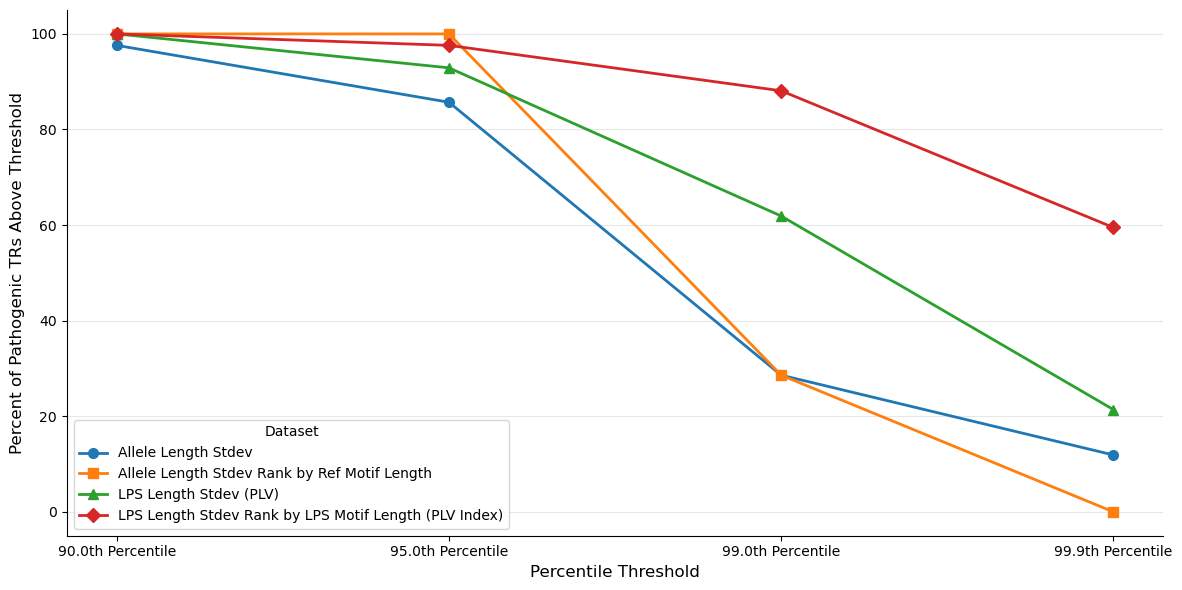

In [24]:
# plot
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
# Collect n_pathogenic_above values for plotting
thresholds = [0.90, 0.95, 0.99, 0.999]
datasets = {
    'Allele Length Stdev': [0.976, 0.857, 0.286, 0.119],
    'Allele Length Stdev Rank by Ref Motif Length': [1.0, 1.0, 0.286, 0.0],
    'LPS Length Stdev (PLV)': [1.0, 0.929, 0.619, 0.214],
    'LPS Length Stdev Rank by LPS Motif Length (PLV Index)': [1.0, 0.976, 0.881, 0.595]
}

# Collect data for plotting
plot_data = []
for dataset_name, dataset in datasets.items():
    for idx, threshold in enumerate(thresholds):
        plot_data.append({
            'Dataset': dataset_name,
            'Threshold': f'{threshold*100:.1f}th Percentile',
            'percent_pathogenic_above': 100*dataset[idx]
        })

# Convert to DataFrame for easier plotting
plot_df = pd.DataFrame(plot_data)

# Create line plot
colorPalette=['#FFF672','#F9A31B','#EB282D','#F1378A','#9D1E89','#195CAC','#06AF9B','#C7D92F','#64CCF5','0.6']
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['svg.fonttype'] = 'none'
fig, ax = plt.subplots(figsize=(12, 6))

# Get unique thresholds and datasets
threshold_labels = [f'{t*100:.1f}th Percentile' for t in thresholds]
dataset_names = list(datasets.keys())

# Set up x positions (same spacing as before)
x = np.arange(len(threshold_labels))

# Plot lines for each dataset
colors = plt.cm.tab10(np.linspace(0, 0.7, 7))
markers = ['o', 's', '^', 'D']
for idx, dataset_name in enumerate(dataset_names):
    data_subset = plot_df[plot_df['Dataset'] == dataset_name]
    values = [data_subset[data_subset['Threshold'] == tl]['percent_pathogenic_above'].values[0]
              for tl in threshold_labels]
    ax.plot(x, values, color=colors[idx], label=dataset_name,
            marker=markers[idx], markersize=7, linewidth=2)

# Customize plot
ax.set_xlabel('Percentile Threshold', fontsize=12)
ax.set_ylabel('Percent of Pathogenic TRs Above Threshold', fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(threshold_labels)
ax.legend(title='Dataset', loc='lower left')
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('figures/SupplementaryFigure5.svg')
plt.savefig('figures/SupplementaryFigure5.png',dpi=600)


In [ ]:
# replicate enrichment with Replication cohort
ONT=pd.read_csv('statsTables/ReplicationCohort_lpsPerMotifStats.TR_Explorer_1.0.1.txt.gz',sep='\t')

# drop to the most common LPS motif per locus
ONT=ONT.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)

# mark pathogenic TRs
ONT['patho']=0
ONT.loc[ONT['TRID'].isin(otherPathogenicTRIDs),'patho']=1

# apply the simplest_motif function the data
ONT['simpleMotif']=ONT.loc[:,'LPS_Motif'].apply(simplest_motif)
ONT['motifLen']=ONT.loc[:,'simpleMotif'].str.len()
# calculate percentile of standard deviation within each motif length grouping
ONT['percentile_stdev']=ONT.groupby('motifLen',observed=True)['std'].rank(pct=True)

# calculate generalized odds ratio for this statistic
group1=ONT.loc[ONT['patho']==1,'percentile_stdev'].dropna().values
group2=ONT.loc[:,'percentile_stdev'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")

Raw U Statistic: 184062171.5
P-Value: 2.7231314867117013e-28
Probability of Superiority: 0.9883
Generalized Odds Ratio: 84.2948


# S6: Replication of enrichment

## S6A

In [ ]:
# caluclate the proportion of the pathogenic TRs that rank above the 90th, 95th, and 99th percentiles
# initial data loading and package import
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sb
import matplotlib
from matplotlib.colors import to_rgba

mpl.rcParams['svg.fonttype'] = 'none'  # keep SVG text in SVGs

highCovComplete=pd.read_csv('statsTables/DiscoveryCohort_lpsPerMotifStats.TR_Explorer_1.0.1.txt.gz',sep='\t')
lowCovComplete=pd.read_csv('statsTables/ValidationCohort_lpsPerMotifStats.TR_Explorer_1.0.1.txt.gz',sep='\t')
AFR=pd.read_csv('statsTables/ValidationCohort_lpsPerMotifStats_AFR.TR_Explorer_1.0.1.txt.gz',sep='\t')
AMR=pd.read_csv('statsTables/ValidationCohort_lpsPerMotifStats_AMR.TR_Explorer_1.0.1.txt.gz',sep='\t')
EUR=pd.read_csv('statsTables/ValidationCohort_lpsPerMotifStats_EUR.TR_Explorer_1.0.1.txt.gz',sep='\t')
EAS=pd.read_csv('statsTables/ValidationCohort_lpsPerMotifStats_EAS.TR_Explorer_1.0.1.txt.gz',sep='\t')
SAS=pd.read_csv('statsTables/ValidationCohort_lpsPerMotifStats_SAS.TR_Explorer_1.0.1.txt.gz',sep='\t')
ONT=pd.read_csv('statsTables/ReplicationCohort_lpsPerMotifStats.TR_Explorer_1.0.1.txt.gz',sep='\t')

# drop to the most common LPS motif per locus
highCovComplete=highCovComplete.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)
lowCovComplete=lowCovComplete.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)
AFR=AFR.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)
AMR=AMR.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)
EUR=EUR.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)
EAS=EAS.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)
SAS=SAS.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)
ONT=ONT.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)

# function to convert motifs to their simplest rotational form with reverse complements
def complement(seq):
    complement = {'A': 'T', 'C': 'G', 'G': 'C', 'T': 'A'} 
    bases = list(seq) 
    bases = [complement[base] for base in bases] 
    return ''.join(bases)
def reverse_complement(seq):
    return complement(seq[::-1])
def simplest_motif(motif):
    i = (motif+motif).find(motif, 1, -1)
    if i != -1:
        motif = motif[:i]
    motifs = []
    b = len(motif)
    for i in range(b):
        c = motif[i:]+motif[:i]
        motifs.append(c)
    motifs = [x.upper() for x in motifs]
    # repeat with reverse complement
    motifRC=reverse_complement(motif.upper())
    i = (motifRC+motifRC).find(motifRC, 1, -1)
    if i != -1:
        motifRC = motifRC[:i]
    b = len(motifRC)
    for i in range(b):
        c = motifRC[i:]+motifRC[:i]
        motifs.append(c)    
    return(min(motifs))

# apply the simplest_motif function the data
highCovComplete['simpleMotif']=highCovComplete.loc[:,'LPS_Motif'].apply(simplest_motif)
lowCovComplete['simpleMotif']=lowCovComplete.loc[:,'LPS_Motif'].apply(simplest_motif)
AFR['simpleMotif']=AFR.loc[:,'LPS_Motif'].apply(simplest_motif)
AMR['simpleMotif']=AMR.loc[:,'LPS_Motif'].apply(simplest_motif)
EUR['simpleMotif']=EUR.loc[:,'LPS_Motif'].apply(simplest_motif)
EAS['simpleMotif']=EAS.loc[:,'LPS_Motif'].apply(simplest_motif)
SAS['simpleMotif']=SAS.loc[:,'LPS_Motif'].apply(simplest_motif)
ONT['simpleMotif']=ONT.loc[:,'LPS_Motif'].apply(simplest_motif)
# calculate percentile of standard deviation within each motif length
highCovComplete['motifLen']=highCovComplete.loc[:,'simpleMotif'].str.len()
lowCovComplete['motifLen']=lowCovComplete.loc[:,'simpleMotif'].str.len()
AFR['motifLen']=AFR.loc[:,'simpleMotif'].str.len()
AMR['motifLen']=AMR.loc[:,'simpleMotif'].str.len()
EUR['motifLen']=EUR.loc[:,'simpleMotif'].str.len()
EAS['motifLen']=EAS.loc[:,'simpleMotif'].str.len()
SAS['motifLen']=SAS.loc[:,'simpleMotif'].str.len()
ONT['motifLen']=ONT.loc[:,'simpleMotif'].str.len()

highCovComplete['percentile_stdev']=highCovComplete.groupby('motifLen',observed=True)['std'].rank(pct=True)
lowCovComplete['percentile_stdev']=lowCovComplete.groupby('motifLen',observed=True)['std'].rank(pct=True)
AFR['percentile_stdev']=AFR.groupby('motifLen',observed=True)['std'].rank(pct=True)
AMR['percentile_stdev']=AMR.groupby('motifLen',observed=True)['std'].rank(pct=True)
EUR['percentile_stdev']=EUR.groupby('motifLen',observed=True)['std'].rank(pct=True)
EAS['percentile_stdev']=EAS.groupby('motifLen',observed=True)['std'].rank(pct=True)
SAS['percentile_stdev']=SAS.groupby('motifLen',observed=True)['std'].rank(pct=True)
ONT['percentile_stdev']=ONT.groupby('motifLen',observed=True)['std'].rank(pct=True)

# Define pathogenic and poly-alanine TRIDs
pathogenic=pd.read_csv('assets/pathogenicTRIDs_TRExplorer_v1.0.1_STRchiveFiltered_noVNTRs_withAnno.txt',sep='\t')

polyAlanineTRNames = ['ARX','NIPA1','HOXA13','PHOX2B','SOX3','HOXD13','ZIC2','RUNX2','PABPN1','FOXL2']
polyAlanineTRIDs = pathogenic.loc[pathogenic['geneName'].isin(polyAlanineTRNames),'TRID'].values
singleShiftTRNames = ['MIR7-2','COMP']
singleShiftTRIDs = pathogenic.loc[pathogenic['geneName'].isin(singleShiftTRNames),'TRID'].values
otherPathogenicTRIDs = pathogenic.loc[~pathogenic['geneName'].isin(polyAlanineTRNames),:]
otherPathogenicTRIDs = otherPathogenicTRIDs.loc[~otherPathogenicTRIDs['geneName'].isin(singleShiftTRNames),'TRID'].values



# Analyze the known pathogenic TR enrichment
highCovComplete['patho']=0
highCovComplete.loc[highCovComplete['TRID'].isin(otherPathogenicTRIDs),'patho']=1
lowCovComplete['patho']=0
lowCovComplete.loc[lowCovComplete['TRID'].isin(otherPathogenicTRIDs),'patho']=1
AFR['patho']=0
AFR.loc[AFR['TRID'].isin(otherPathogenicTRIDs),'patho']=1
AMR['patho']=0
AMR.loc[AMR['TRID'].isin(otherPathogenicTRIDs),'patho']=1
EUR['patho']=0
EUR.loc[EUR['TRID'].isin(otherPathogenicTRIDs),'patho']=1
EAS['patho']=0
EAS.loc[EAS['TRID'].isin(otherPathogenicTRIDs),'patho']=1
SAS['patho']=0
SAS.loc[SAS['TRID'].isin(otherPathogenicTRIDs),'patho']=1
ONT['patho']=0
ONT.loc[ONT['TRID'].isin(otherPathogenicTRIDs),'patho']=1

from statsmodels.stats.contingency_tables import Table2x2

def calculate_enrichment_with_ci(df, percentile_threshold, pathogenic_col='patho'):
    above_threshold = df['percentile_stdev'] > percentile_threshold
    
    a = ((df[pathogenic_col] == 1) & above_threshold).sum()
    b = ((df[pathogenic_col] == 0) & above_threshold).sum()
    c = ((df[pathogenic_col] == 1) & ~above_threshold).sum()
    d = ((df[pathogenic_col] == 0) & ~above_threshold).sum()
    
    table = Table2x2([[a, b], [c, d]])
    
    return {
        'odds_ratio': table.oddsratio,
        'p_value': table.oddsratio_pvalue(),
        'ci_95': table.oddsratio_confint(alpha=0.05),
        'contingency_table': [[a, b], [c, d]],
        'n_pathogenic_above': a,
        'n_pathogenic_total': a + c,
        'n_total_above': a + b
    }
# Collect n_pathogenic_above values for plotting
thresholds = [0.90, 0.95, 0.99, 0.999]
datasets = {
    'Discovery Cohort': highCovComplete,
    'Validation Cohort (All Ancestries)': lowCovComplete,
    'AFR-only (Validation Cohort)': AFR,
    'AMR-only (Validation Cohort)': AMR,
    'EUR-only (Validation Cohort)': EUR,
    'EAS-only (Validation Cohort)': EAS,
    'SAS-only (Validation Cohort)': SAS,
    'Replication Cohort': ONT
}

# Collect data for plotting
plot_data = []
for dataset_name, dataset in datasets.items():
    for threshold in thresholds:
        stats = calculate_enrichment_with_ci(dataset, threshold)
        plot_data.append({
            'Dataset': dataset_name,
            'Threshold': f'{threshold*100:.1f}th Percentile',
            'percent_pathogenic_above': 100*stats['n_pathogenic_above']/42
        })

# Convert to DataFrame for easier plotting
plot_df = pd.DataFrame(plot_data)


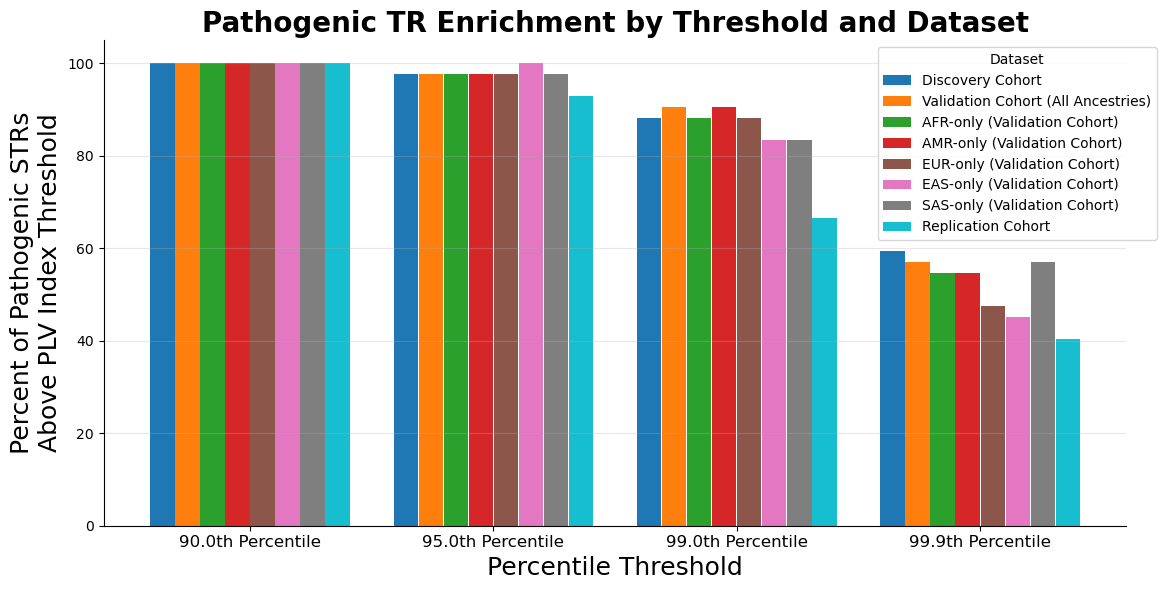

In [8]:

# Create grouped bar plot
colorPalette=['#FFF672','#F9A31B','#EB282D','#F1378A','#9D1E89','#195CAC','#06AF9B','#C7D92F','#64CCF5','0.6']
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['svg.fonttype'] = 'none'
fig, ax = plt.subplots(figsize=(12, 6))

# Get unique thresholds and datasets
threshold_labels = [f'{t*100:.1f}th Percentile' for t in thresholds]
dataset_names = list(datasets.keys())

# Set up bar positions
x = np.arange(len(threshold_labels))
width = 0.1
offsets = np.linspace(-width*3.6, width*3.6, len(dataset_names))

# Plot bars for each dataset
colors = plt.cm.tab10(np.linspace(0, 0.9, len(dataset_names)))
for idx, dataset_name in enumerate(dataset_names):
    data_subset = plot_df[plot_df['Dataset'] == dataset_name]
    values = [data_subset[data_subset['Threshold'] == tl]['percent_pathogenic_above'].values[0] 
              for tl in threshold_labels]
    ax.bar(x + offsets[idx], values, width, label=dataset_name, color=colors[idx])

# Customize plot
ax.set_xlabel('Percentile Threshold', fontsize=18)
ax.set_ylabel('Percent of Pathogenic STRs\nAbove PLV Index Threshold', fontsize=18)
ax.set_title('Pathogenic TR Enrichment by Threshold and Dataset', fontsize=20, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(threshold_labels,fontsize=12)
ax.legend(title='Dataset', bbox_to_anchor=(0.75, 1), loc='upper left')
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('figures/SupplementaryFigure6A.png',dpi=600)
plt.savefig('figures/SupplementaryFigure6A.svg')


## S6B

In [ ]:
# Adotto catalog version
# initial data loading and package import
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sb
import matplotlib
from matplotlib.colors import to_rgba

mpl.rcParams['svg.fonttype'] = 'none'  # keep SVG text in SVGs

highCovComplete=pd.read_csv('statsTables/DiscoveryCohort_lpsPerMotifStats.Adotto.txt.gz',sep='\t')
lowCovComplete=pd.read_csv('statsTables/ValidationCohort_lpsPerMotifStats.Adotto.txt.gz',sep='\t')
AFR=pd.read_csv('statsTables/ValidationCohort_lpsPerMotifStats_AFR.Adotto.txt.gz',sep='\t')
AMR=pd.read_csv('statsTables/ValidationCohort_lpsPerMotifStats_AMR.Adotto.txt.gz',sep='\t')
EUR=pd.read_csv('statsTables/ValidationCohort_lpsPerMotifStats_EUR.Adotto.txt.gz',sep='\t')
EAS=pd.read_csv('statsTables/ValidationCohort_lpsPerMotifStats_EAS.Adotto.txt.gz',sep='\t')
SAS=pd.read_csv('statsTables/ValidationCohort_lpsPerMotifStats_SAS.Adotto.txt.gz',sep='\t')


# drop to the most common LPS motif per locus
highCovComplete=highCovComplete.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)
lowCovComplete=lowCovComplete.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)
AFR=AFR.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)
AMR=AMR.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)
EUR=EUR.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)
EAS=EAS.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)
SAS=SAS.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)

# function to convert motifs to their simplest rotational form with reverse complements
def complement(seq):
    complement = {'A': 'T', 'C': 'G', 'G': 'C', 'T': 'A'} 
    bases = list(seq) 
    bases = [complement[base] for base in bases] 
    return ''.join(bases)
def reverse_complement(seq):
    return complement(seq[::-1])
def simplest_motif(motif):
    i = (motif+motif).find(motif, 1, -1)
    if i != -1:
        motif = motif[:i]
    motifs = []
    b = len(motif)
    for i in range(b):
        c = motif[i:]+motif[:i]
        motifs.append(c)
    motifs = [x.upper() for x in motifs]
    # repeat with reverse complement
    motifRC=reverse_complement(motif.upper())
    i = (motifRC+motifRC).find(motifRC, 1, -1)
    if i != -1:
        motifRC = motifRC[:i]
    b = len(motifRC)
    for i in range(b):
        c = motifRC[i:]+motifRC[:i]
        motifs.append(c)    
    return(min(motifs))

# apply the simplest_motif function the data
highCovComplete['simpleMotif']=highCovComplete.loc[:,'LPS_Motif'].apply(simplest_motif)
lowCovComplete['simpleMotif']=lowCovComplete.loc[:,'LPS_Motif'].apply(simplest_motif)
AFR['simpleMotif']=AFR.loc[:,'LPS_Motif'].apply(simplest_motif)
AMR['simpleMotif']=AMR.loc[:,'LPS_Motif'].apply(simplest_motif)
EUR['simpleMotif']=EUR.loc[:,'LPS_Motif'].apply(simplest_motif)
EAS['simpleMotif']=EAS.loc[:,'LPS_Motif'].apply(simplest_motif)
SAS['simpleMotif']=SAS.loc[:,'LPS_Motif'].apply(simplest_motif)

highCovComplete['motifLen']=highCovComplete.loc[:,'simpleMotif'].str.len()
lowCovComplete['motifLen']=lowCovComplete.loc[:,'simpleMotif'].str.len()
AFR['motifLen']=AFR.loc[:,'simpleMotif'].str.len()
AMR['motifLen']=AMR.loc[:,'simpleMotif'].str.len()
EUR['motifLen']=EUR.loc[:,'simpleMotif'].str.len()
EAS['motifLen']=EAS.loc[:,'simpleMotif'].str.len()
SAS['motifLen']=SAS.loc[:,'simpleMotif'].str.len()

# calculate percentile of standard deviation within each motif group length
highCovComplete['percentile_stdev']=highCovComplete.groupby('motifLen',observed=True)['std'].rank(pct=True)
lowCovComplete['percentile_stdev']=lowCovComplete.groupby('motifLen',observed=True)['std'].rank(pct=True)
AFR['percentile_stdev']=AFR.groupby('motifLen',observed=True)['std'].rank(pct=True)
AMR['percentile_stdev']=AMR.groupby('motifLen',observed=True)['std'].rank(pct=True)
EUR['percentile_stdev']=EUR.groupby('motifLen',observed=True)['std'].rank(pct=True)
EAS['percentile_stdev']=EAS.groupby('motifLen',observed=True)['std'].rank(pct=True)
SAS['percentile_stdev']=SAS.groupby('motifLen',observed=True)['std'].rank(pct=True)

# Define pathogenic and poly-alanine TRIDs
pathogenic=pd.read_csv('assets/pathogenicTRs_ageOfOnset_STRchiveVersion_Adotto.txt',sep='\t')
pathogenic=pathogenic.rename(columns={'TRName':'geneName'})

polyAlanineTRNames = ['ARX','NIPA1','HOXA13','PHOX2B','SOX3','HOXD13','ZIC2','RUNX2','PABPN1','FOXL2']
polyAlanineTRIDs = pathogenic.loc[pathogenic['geneName'].isin(polyAlanineTRNames),'TRID'].values
singleShiftTRNames = ['MIR7-2','COMP']
singleShiftTRIDs = pathogenic.loc[pathogenic['geneName'].isin(singleShiftTRNames),'TRID'].values
otherPathogenicTRIDs = pathogenic.loc[~pathogenic['geneName'].isin(polyAlanineTRNames),:]
otherPathogenicTRIDs = otherPathogenicTRIDs.loc[~otherPathogenicTRIDs['geneName'].isin(singleShiftTRNames),'TRID'].values



In [6]:
# Analyze the known pathogenic TR enrichment
highCovComplete['patho']=0
highCovComplete.loc[highCovComplete['TRID'].isin(otherPathogenicTRIDs),'patho']=1
lowCovComplete['patho']=0
lowCovComplete.loc[lowCovComplete['TRID'].isin(otherPathogenicTRIDs),'patho']=1
AFR['patho']=0
AFR.loc[AFR['TRID'].isin(otherPathogenicTRIDs),'patho']=1
AMR['patho']=0
AMR.loc[AMR['TRID'].isin(otherPathogenicTRIDs),'patho']=1
EUR['patho']=0
EUR.loc[EUR['TRID'].isin(otherPathogenicTRIDs),'patho']=1
EAS['patho']=0
EAS.loc[EAS['TRID'].isin(otherPathogenicTRIDs),'patho']=1
SAS['patho']=0
SAS.loc[SAS['TRID'].isin(otherPathogenicTRIDs),'patho']=1

from statsmodels.stats.contingency_tables import Table2x2

def calculate_enrichment_with_ci(df, percentile_threshold, pathogenic_col='patho'):
    above_threshold = df['percentile_stdev'] > percentile_threshold
    
    a = ((df[pathogenic_col] == 1) & above_threshold).sum()
    b = ((df[pathogenic_col] == 0) & above_threshold).sum()
    c = ((df[pathogenic_col] == 1) & ~above_threshold).sum()
    d = ((df[pathogenic_col] == 0) & ~above_threshold).sum()
    
    table = Table2x2([[a, b], [c, d]])
    
    return {
        'odds_ratio': table.oddsratio,
        'p_value': table.oddsratio_pvalue(),
        'ci_95': table.oddsratio_confint(alpha=0.05),
        'contingency_table': [[a, b], [c, d]],
        'n_pathogenic_above': a,
        'n_pathogenic_total': a + c,
        'n_total_above': a + b
    }


print("\n\n=== Select Pathogenic TRs (excluding polyAlanine and singleShift TRs) ===")
for threshold in [0.90, 0.95, 0.99, 0.999]:
    for dataset in [highCovComplete, lowCovComplete, AFR, AMR, EUR, EAS, SAS]:
        stats = calculate_enrichment_with_ci(dataset, threshold)
        print(f"\nAbove {threshold*100:.1f}th percentile:")
        print(f"  Contingency table: {stats['contingency_table']}")
        print(f"  Odds Ratio: {stats['odds_ratio']:.2f}")
        print(f"  Confidence Interval: {stats['ci_95']}")
        print(f"  P-value: {stats['p_value']:.2e}")
        print(f"  Pathogenic above threshold: {stats['n_pathogenic_above']}/{stats['n_pathogenic_total']} ({stats['n_pathogenic_above']/stats['n_pathogenic_total']:.1%})")
        print("")




=== Select Pathogenic TRs (excluding polyAlanine and singleShift TRs) ===

Above 90.0th percentile:
  Contingency table: [[41, 178574], [1, 1605644]]
  Odds Ratio: 368.65
  Confidence Interval: (50.70990064221233, 2680.0137472075567)
  P-value: 5.25e-09
  Pathogenic above threshold: 41/42 (97.6%)


Above 90.0th percentile:
  Contingency table: [[41, 178540], [1, 1605754]]
  Odds Ratio: 368.75
  Confidence Interval: (50.723032169154514, 2680.7077525551363)
  P-value: 5.24e-09
  Pathogenic above threshold: 41/42 (97.6%)


Above 90.0th percentile:
  Contingency table: [[41, 178537], [1, 1605744]]
  Odds Ratio: 368.75
  Confidence Interval: (50.72356858734317, 2680.7361027175425)
  P-value: 5.24e-09
  Pathogenic above threshold: 41/42 (97.6%)


Above 90.0th percentile:
  Contingency table: [[41, 178509], [1, 1605685]]
  Odds Ratio: 368.79
  Confidence Interval: (50.72966074702145, 2681.058077496536)
  P-value: 5.24e-09
  Pathogenic above threshold: 41/42 (97.6%)


Above 90.0th percentile

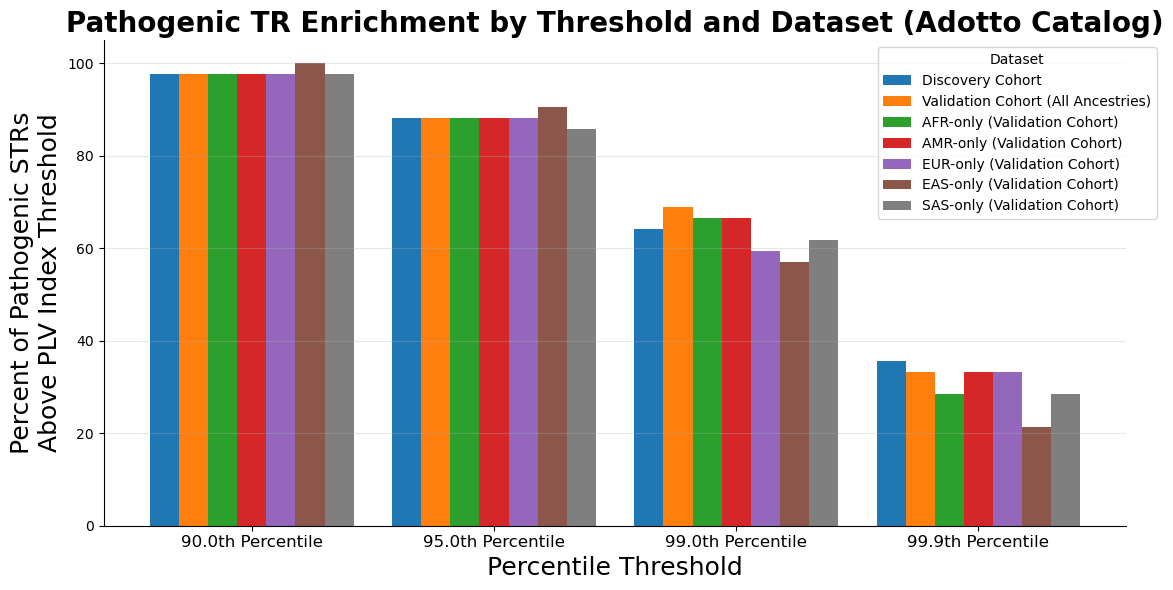

In [7]:
# Collect n_pathogenic_above values for plotting
thresholds = [0.90, 0.95, 0.99, 0.999]
datasets = {
    'Discovery Cohort': highCovComplete,
    'Validation Cohort (All Ancestries)': lowCovComplete,
    'AFR-only (Validation Cohort)': AFR,
    'AMR-only (Validation Cohort)': AMR,
    'EUR-only (Validation Cohort)': EUR,
    'EAS-only (Validation Cohort)': EAS,
    'SAS-only (Validation Cohort)': SAS
}

# Collect data for plotting
plot_data = []
for dataset_name, dataset in datasets.items():
    for threshold in thresholds:
        stats = calculate_enrichment_with_ci(dataset, threshold)
        plot_data.append({
            'Dataset': dataset_name,
            'Threshold': f'{threshold*100:.1f}th Percentile',
            'percent_pathogenic_above': 100*stats['n_pathogenic_above']/42
        })

# Convert to DataFrame for easier plotting
plot_df = pd.DataFrame(plot_data)

# Create grouped bar plot
colorPalette=['#FFF672','#F9A31B','#EB282D','#F1378A','#9D1E89','#195CAC','#06AF9B','#C7D92F','#64CCF5','0.6']
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['svg.fonttype'] = 'none'
fig, ax = plt.subplots(figsize=(12, 6))

# Get unique thresholds and datasets
threshold_labels = [f'{t*100:.1f}th Percentile' for t in thresholds]
dataset_names = list(datasets.keys())

# Set up bar positions
x = np.arange(len(threshold_labels))
width = 0.12
offsets = np.linspace(-width*3, width*3, len(dataset_names))

# Plot bars for each dataset
colors = plt.cm.tab10(np.linspace(0, 0.7, len(dataset_names)))
for idx, dataset_name in enumerate(dataset_names):
    data_subset = plot_df[plot_df['Dataset'] == dataset_name]
    values = [data_subset[data_subset['Threshold'] == tl]['percent_pathogenic_above'].values[0] 
              for tl in threshold_labels]
    ax.bar(x + offsets[idx], values, width, label=dataset_name, color=colors[idx])

# Customize plot
ax.set_xlabel('Percentile Threshold', fontsize=18)
ax.set_ylabel('Percent of Pathogenic STRs\nAbove PLV Index Threshold', fontsize=18)
ax.set_title('Pathogenic TR Enrichment by Threshold and Dataset (Adotto Catalog)', fontsize=20, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(threshold_labels, fontsize=12)
ax.legend(title='Dataset', bbox_to_anchor=(0.75, 1), loc='upper left')
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('figures/SupplementaryFigure6B.png',dpi=600)
plt.savefig('figures/SupplementaryFigure6B.svg')


# S7: Limitations of disease-associated TR Enrichment with Population Variation

## S7A

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib as mpl
from collections import Counter, defaultdict
import argparse
import sys


def get_canonical_kmer(kmer):
    """
    Get the lexicographically smallest rotation of a k-mer.

    For example, 'GAAGG' and 'AAGGG' both return 'AAGGG'.
    """
    if not kmer:
        return kmer

    # Generate all rotations and return the lexicographically smallest
    rotations = [kmer[i:] + kmer[:i] for i in range(len(kmer))]
    return min(rotations)


def get_all_rotations(kmer):
    """
    Get all rotations of a k-mer.
    """
    return [kmer[i:] + kmer[:i] for i in range(len(kmer))]


def extract_all_kmers(sequences, k_sizes):
    """
    Extract all k-mers of specified sizes from all sequences.

    Args:
        sequences: List of sequences to extract k-mers from
        k_sizes: List of k-mer sizes to extract (e.g., [3, 5, 6])

    Returns a Counter of canonical k-mer frequencies.
    """
    kmer_counts = Counter()

    for seq in sequences:
        if pd.isna(seq) or seq == '':
            continue
        seq = str(seq).upper()

        # Extract k-mers of specified sizes
        for k in k_sizes:
            if k > len(seq):
                continue
            for i in range(len(seq) - k + 1):
                kmer = seq[i:i+k]
                # Convert to canonical form (lexicographically smallest rotation)
                canonical = get_canonical_kmer(kmer)
                kmer_counts[canonical] += 1

    return kmer_counts


def is_perfect_repetition(kmer):
    """
    Check if a k-mer is a perfect repetition of a shorter k-mer.

    For example, 'AAGAAGAAGAAG' is a perfect repetition of 'AAG'.
    Returns (True, base_kmer) if it's a perfect repetition, (False, None) otherwise.
    """
    kmer_len = len(kmer)

    # Try all possible divisor lengths
    for base_len in range(1, kmer_len):
        if kmer_len % base_len == 0:
            # Check if kmer is made of perfect repetitions of the base
            num_reps = kmer_len // base_len
            base = kmer[:base_len]
            if base * num_reps == kmer:
                return True, base

    return False, None


def filter_subsequence_kmers(kmer_counts, sequences):
    """
    Filter out k-mers that only appear as subsequences of other k-mers.

    If k-mer A is a subsequence of k-mer B, and all occurrences of A
    are within occurrences of B, then A is removed.
    Works with canonical k-mers and their rotations.

    Also filters out k-mers that are perfect repetitions of shorter k-mers.
    """
    # Sort k-mers by length (longest first) then by frequency (most frequent first)
    sorted_kmers = sorted(kmer_counts.items(), key=lambda x: (len(x[0]), x[1]), reverse=True)

    filtered_kmers = {}
    removed_kmers = set()
    repetition_removed = []

    for kmer, count in sorted_kmers:
        if kmer in removed_kmers:
            continue

        # Filter out k-mers that are perfect repetitions of shorter k-mers
        is_rep, base = is_perfect_repetition(kmer)
        if is_rep:
            # Check if the base k-mer (or its canonical form) exists
            canonical_base = get_canonical_kmer(base)
            if canonical_base in kmer_counts:
                removed_kmers.add(kmer)
                repetition_removed.append((kmer, canonical_base))
                continue

        # Check if this k-mer is a subsequence of any larger, already-accepted k-mer
        is_pure_subsequence = False

        for larger_kmer in filtered_kmers:
            # Check if any rotation of kmer appears in any rotation of larger_kmer
            kmer_rotations = get_all_rotations(kmer)
            larger_rotations = get_all_rotations(larger_kmer)

            is_subsequence = False
            for kr in kmer_rotations:
                for lr in larger_rotations:
                    if len(lr) > len(kr) and kr in lr:
                        is_subsequence = True
                        break
                if is_subsequence:
                    break

            if not is_subsequence:
                continue

            # Count how many times kmer appears independently vs within larger_kmer
            independent_count = 0
            within_larger_count = 0

            for seq in sequences:
                if pd.isna(seq) or seq == '':
                    continue
                seq = str(seq).upper()

                # Find all occurrences of any rotation of larger_kmer
                larger_positions = []
                for lr in larger_rotations:
                    start = 0
                    while True:
                        pos = seq.find(lr, start)
                        if pos == -1:
                            break
                        larger_positions.append((pos, pos + len(lr)))
                        start = pos + 1

                # Find all occurrences of any rotation of kmer
                for kr in kmer_rotations:
                    start = 0
                    while True:
                        pos = seq.find(kr, start)
                        if pos == -1:
                            break

                        # Check if this occurrence is within any larger_kmer occurrence
                        is_within = False
                        for lstart, lend in larger_positions:
                            if pos >= lstart and pos + len(kr) <= lend:
                                is_within = True
                                break

                        if is_within:
                            within_larger_count += 1
                        else:
                            independent_count += 1

                        start = pos + 1

            # If all occurrences are within the larger k-mer, mark as pure subsequence
            if independent_count == 0 and within_larger_count > 0:
                is_pure_subsequence = True
                break

        if not is_pure_subsequence:
            filtered_kmers[kmer] = count
        else:
            removed_kmers.add(kmer)

    # Print diagnostic information about filtered repetitions
    if repetition_removed:
        print(f"\nFiltered {len(repetition_removed)} k-mers that are perfect repetitions:")
        for kmer, base in repetition_removed[:10]:  # Show first 10
            num_reps = len(kmer) // len(base)
            print(f"  {kmer} ({len(kmer)}bp) = {num_reps}x {base} ({len(base)}bp)")
        if len(repetition_removed) > 10:
            print(f"  ... and {len(repetition_removed) - 10} more")

    return filtered_kmers


def decompose_sequence(seq, top_kmers):
    """
    Decompose a sequence into k-mers, prioritizing longer and more common k-mers.
    Matches any rotation of the canonical k-mers.

    Returns a list of (kmer, length, position) tuples where:
    - kmer: the canonical k-mer or 'other'
    - length: the actual length of the matched segment
    - position: the starting position in the sequence
    """
    if pd.isna(seq) or seq == '':
        return []

    seq = str(seq).upper()
    decomposition = []

    # Sort k-mers by length (longest first) then by frequency (most common first)
    sorted_kmers = sorted(top_kmers, key=lambda x: (len(x), top_kmers[x]), reverse=True)

    position = 0
    while position < len(seq):
        matched = False

        # Try to match k-mers starting from longest
        for canonical_kmer in sorted_kmers:
            # Try all rotations of this canonical k-mer
            rotations = get_all_rotations(canonical_kmer)
            for rotation in rotations:
                if seq[position:position+len(rotation)] == rotation:
                    # Store the canonical form with the actual matched length
                    decomposition.append((canonical_kmer, len(rotation), position))
                    position += len(rotation)
                    matched = True
                    break
            if matched:
                break

        # If no match, add as 'other' with length 1
        if not matched:
            decomposition.append(('other', 1, position))
            position += 1

    # Merge consecutive 'other' segments to avoid thin lines in the plot
    merged_decomposition = []
    for kmer, length, pos in decomposition:
        if kmer == 'other' and merged_decomposition and merged_decomposition[-1][0] == 'other':
            # Extend the previous 'other' segment
            prev_kmer, prev_length, prev_pos = merged_decomposition[-1]
            merged_decomposition[-1] = (prev_kmer, prev_length + length, prev_pos)
        else:
            merged_decomposition.append((kmer, length, pos))

    return merged_decomposition


def create_waterfall_plot(df, output_file_base='waterfall_plot', k_sizes=None, N_kmers=10):
    """
    Create a waterfall plot showing k-mer composition of alleles.

    Args:
        df: DataFrame with allele1 and allele2 columns
        output_file_base: Output file name without file extension
        k_sizes: List of k-mer sizes to extract (e.g., [3, 5, 6])
    """
    if k_sizes is None:
        k_sizes = list(range(1, 16))  # Default: 1-15
    # Collect all sequences
    all_sequences = []

    for _, row in df.iterrows():
        if 'allele1' in row and not pd.isna(row['allele1']):
            all_sequences.append(str(row['allele1']).upper())
        if 'allele2' in row and not pd.isna(row['allele2']):
            all_sequences.append(str(row['allele2']).upper())

    if not all_sequences:
        print("Error: No valid allele sequences found in input file.")
        sys.exit(1)

    print(f"Found {len(all_sequences)} total alleles.")

    # Group by unique alleles and count occurrences
    allele_counts = Counter(all_sequences)
    print(f"Found {len(allele_counts)} unique alleles.")

    # Use all unique alleles, sorted by length then alphabetically
    allele_data = sorted(allele_counts.items(),
                         key=lambda x: (len(x[0]), x[0]),
                         reverse=False)
    print(f"Plotting all {len(allele_data)} alleles.")
    all_sequences = [a[0] for a in allele_data]


    # Extract all k-mers (use all sequences for frequency calculation)
    print(f"Extracting k-mers (sizes: {sorted(k_sizes)})...")
    kmer_counts = extract_all_kmers(all_sequences, k_sizes)
    print(f"Found {len(kmer_counts)} unique k-mers.")

    # Filter subsequence k-mers
    print("Filtering subsequence k-mers...")
    filtered_kmers = filter_subsequence_kmers(kmer_counts, all_sequences)
    print(f"After filtering: {len(filtered_kmers)} k-mers remain.")

    # Get top N k-mers
    top_N_kmers = dict(Counter(filtered_kmers).most_common(N_kmers))
    print(f"\nTop {N_kmers} k-mers:")
    for kmer, count in top_N_kmers.items():
        print(f"  {kmer}: {count} occurrences")

    # Create color map
    colors = plt.cm.tab10(range(10))
    kmer_colors = {kmer: colors[i] for i, kmer in enumerate(top_N_kmers.keys())}
    kmer_colors['other'] = "#404040"

    # Create plot with two subplots: main waterfall and count bar
    mpl.rcParams['pdf.fonttype'] = 42
    mpl.rcParams['svg.fonttype'] = 'none'
    fig = plt.figure(figsize=(8,10))

    # Main waterfall plot (left side, takes up most space)
    ax_main = plt.subplot2grid((1, 20), (0, 0), colspan=17)

    # Count bar plot (right side, narrow)
    ax_count = plt.subplot2grid((1, 20), (0, 17), colspan=3)

    y_positions = range(len(allele_data))

    # Plot alleles as segmented sequences
    for i, (seq, count) in enumerate(allele_data):
        decomposition = decompose_sequence(seq, top_N_kmers)

        # Validate complete coverage
        total_length = sum(length for _, length, _ in decomposition)
        if total_length != len(seq):
            print(f"Warning: Sequence {i} has incomplete coverage: {total_length} != {len(seq)}")

        # Plot each k-mer segment
        current_pos = 0
        for kmer, length, _ in decomposition:
            color = kmer_colors.get(kmer, kmer_colors['other'])

            ax_main.barh(i, length, left=current_pos, height=0.8,
                        color=color, edgecolor='none', linewidth=0)
            current_pos += length

    # Set labels for main plot
    max_length = max(len(seq) for seq, _ in allele_data)

    ax_main.set_yticks([])
    ax_main.set_xlabel('Position (bp)', fontsize=20)
    ax_main.tick_params(labelsize=14)
    #ax_main.set_title('Tandem Repeat Allele Composition - Waterfall Plot', fontsize=14, fontweight='bold')
    ax_main.set_xlim(0, max_length *  1.01)

    # Plot observation counts
    counts = [count for _, count in allele_data]
    ax_count.barh(y_positions, counts, height=0.8, color='#4CAF50', alpha=0.7)
    ax_count.set_yticks(y_positions)
    ax_count.set_yticklabels([])  # No labels, shared with main plot
    ax_count.set_xlabel('Count', fontsize=14)
    ax_count.tick_params(labelsize=10)
    #ax_count.set_title('Obs.', fontsize=14)
    ax_count.set_xlim(0, max(counts) * 1.2)

    # Add count values as text
    for i, count in enumerate(counts):
        ax_count.text(count + max(counts) * 0.02, i, str(count),
                     va='center', ha='left', fontsize=8)

    # Create legend
    legend_elements = [mpatches.Patch(facecolor=kmer_colors[kmer], label=kmer)
                      for kmer in top_N_kmers.keys()]
    legend_elements.append(mpatches.Patch(facecolor=kmer_colors['other'], label='other'))

    ax_main.legend(handles=legend_elements,
                  title='LPS Motif', fontsize=14)

    plt.tight_layout()
    plt.savefig(f'{output_file_base}.svg', bbox_inches='tight')
    plt.savefig(f'{output_file_base}.png',dpi=600, bbox_inches='tight')
    print(f"\nWaterfall plot saved to: {output_file_base}")
    plt.close()


In [34]:
import pandas
allDiseaseAssociatedAlleles=pandas.read_csv('assets/pathogenicSTRs_alleleInfo_noIDs.txt',sep='\t',header=None,names=['TRID','allele1','allele2','allele1_lps_length','allele1_lps_motif','allele2_lps_length','allele2_lps_motif','allele1_len','allele2_len'])
phox2bAlleles=allDiseaseAssociatedAlleles.loc[allDiseaseAssociatedAlleles['TRID']=='4-41745972-41746032-GCN',:]
outputBaseName="figures/SupplementaryFigure17A"
kmers=[3]
create_waterfall_plot(phox2bAlleles, outputBaseName, kmers, N_kmers=4)


Found 1086 total alleles.
Found 12 unique alleles.
Plotting all 12 alleles.
Extracting k-mers (sizes: [3])...
Found 7 unique k-mers.
Filtering subsequence k-mers...
After filtering: 7 k-mers remain.

Top 4 k-mers:
  CCG: 333 occurrences
  CTG: 229 occurrences
  CGG: 45 occurrences
  AGC: 11 occurrences

Waterfall plot saved to: figures/SupplementaryFigure17A


## S7B

In [35]:
runx2Alleles=allDiseaseAssociatedAlleles.loc[allDiseaseAssociatedAlleles['TRID']=='6-45422750-45422792-GCN',:]
outputBaseName="figures/SupplementaryFigure17B"
kmers=[3]
create_waterfall_plot(runx2Alleles, outputBaseName, kmers, N_kmers=4)


Found 1086 total alleles.
Found 10 unique alleles.
Plotting all 10 alleles.
Extracting k-mers (sizes: [3])...
Found 6 unique k-mers.
Filtering subsequence k-mers...
After filtering: 6 k-mers remain.

Top 4 k-mers:
  CGG: 254 occurrences
  CTG: 45 occurrences
  AGC: 43 occurrences
  AGG: 8 occurrences

Waterfall plot saved to: figures/SupplementaryFigure17B


## S7C

In [ ]:
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sb
import matplotlib
from matplotlib.colors import to_rgba
import scipy.stats

mpl.rcParams['svg.fonttype'] = 'none'  # keep SVG text in SVGs

totalLen=pd.read_csv('statsTables/DiscoveryCohort_alleleLengthStats.TR_Explorer_1.0.1.txt.gz',sep='\t')

# calculate percentile of standard deviation
totalLen['percentile_stdev']=totalLen.loc[:,'std'].rank(pct=True)

# Define pathogenic and poly-alanine TRIDs
pathogenic=pd.read_csv('assets/pathogenicTRIDs_TRExplorer_v1.0.1_STRchiveFiltered_noVNTRs_withAnno.txt',sep='\t')
polyAlanineTRNames = ['ARX','NIPA1','HOXA13','PHOX2B','SOX3','HOXD13','ZIC2','RUNX2','PABPN1','FOXL2']
polyAlanineTRIDs = pathogenic.loc[pathogenic['geneName'].isin(polyAlanineTRNames),'TRID'].values
singleShiftTRNames = ['MIR7-2','COMP']
singleShiftTRIDs = pathogenic.loc[pathogenic['geneName'].isin(singleShiftTRNames),'TRID'].values
otherPathogenicTRIDs = pathogenic.loc[~pathogenic['geneName'].isin(polyAlanineTRNames),:]
otherPathogenicTRIDs = otherPathogenicTRIDs.loc[~otherPathogenicTRIDs['geneName'].isin(singleShiftTRNames),'TRID'].values

# define pathogenic VNTRs
vntrs=pd.read_csv('assets/pathogenicTRIDs_TRExplorer_v1.0.1_STRchiveVNTRs.txt',sep='\t')
vntrTRIDs = vntrs.loc[:,'TRID'].values

# mark pathogenic TRs
totalLen['patho']=0
totalLen.loc[totalLen['TRID'].isin(polyAlanineTRIDs),'patho']=1

# calculate generalized odds ratio for the poly-alanine set
group1=totalLen.loc[totalLen['patho']==1,'std'].dropna().values
group2=totalLen.loc[:,'std'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Poly-Alanine Loci:")
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")
print()


# repeat for single shifters
totalLen['patho']=0
totalLen.loc[totalLen['TRID'].isin(singleShiftTRIDs),'patho']=1

# calculate generalized odds ratio for the single shift set
group1=totalLen.loc[totalLen['patho']==1,'std'].dropna().values
group2=totalLen.loc[:,'std'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Single Shift Loci:")
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")
print()

# repeat for single shifters
totalLen['patho']=0
totalLen.loc[totalLen['TRID'].isin(vntrTRIDs),'patho']=1

# calculate generalized odds ratio for the VNTR set
group1=totalLen.loc[totalLen['patho']==1,'std'].dropna().values
group2=totalLen.loc[:,'std'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"VNTR Loci:")
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")
print()


Poly-Alanine Loci:
Raw U Statistic: 26470938.5
P-Value: 0.03711552707713488
Probability of Superiority: 0.6625
Generalized Odds Ratio: 1.9628

Single Shift Loci:
Raw U Statistic: 5018393.5
P-Value: 0.3678464508521456
Probability of Superiority: 0.5652
Generalized Odds Ratio: 1.2998

VNTR Loci:
Raw U Statistic: 16292034.0
P-Value: 0.0011165375031031855
Probability of Superiority: 0.9174
Generalized Odds Ratio: 11.1084



In [14]:
# repeat, normalized to reference motif 
# calculate reference motif  
totalLen[['chr','start','end','refMotif']]=totalLen.loc[:,'TRID'].str.split(',',expand=True).iloc[:,0].str.split('-',expand=True)
totalLen['motifLen']=totalLen.loc[:,'refMotif'].str.len()

# calculate percentile of standard deviation grouped by ref motif length
totalLen['percentile_stdev']=totalLen.groupby('motifLen',observed=True)['std'].rank(pct=True)

# mark pathogenic TRs
totalLen['patho']=0
totalLen.loc[totalLen['TRID'].isin(polyAlanineTRIDs),'patho']=1

# calculate generalized odds ratio for the poly-alanine set
group1=totalLen.loc[totalLen['patho']==1,'percentile_stdev'].dropna().values
group2=totalLen.loc[:,'percentile_stdev'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Poly-Alanine Loci:")
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")
print()


# repeat for single shifters
totalLen['patho']=0
totalLen.loc[totalLen['TRID'].isin(singleShiftTRIDs),'patho']=1

# calculate generalized odds ratio for the single shift set
group1=totalLen.loc[totalLen['patho']==1,'percentile_stdev'].dropna().values
group2=totalLen.loc[:,'percentile_stdev'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Single Shift Loci:")
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")
print()

# repeat for single shifters
totalLen['patho']=0
totalLen.loc[totalLen['TRID'].isin(vntrTRIDs),'patho']=1

# calculate generalized odds ratio for the VNTR set
group1=totalLen.loc[totalLen['patho']==1,'percentile_stdev'].dropna().values
group2=totalLen.loc[:,'percentile_stdev'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"VNTR Loci:")
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")
print()


Poly-Alanine Loci:
Raw U Statistic: 32989614.5
P-Value: 0.00031822193532678503
Probability of Superiority: 0.8256
Generalized Odds Ratio: 4.7348

Single Shift Loci:
Raw U Statistic: 6825546.5
P-Value: 0.09198404974947844
Probability of Superiority: 0.7687
Generalized Odds Ratio: 3.3234

VNTR Loci:
Raw U Statistic: 12714649.0
P-Value: 0.06549226424356484
Probability of Superiority: 0.7160
Generalized Odds Ratio: 2.5207



In [ ]:
# repeat for LPS length
lps=pd.read_csv('statsTables/DiscoveryCohort_lpsPerMotifStats.TR_Explorer_1.0.1.txt.gz',sep='\t')

# drop to the most common LPS motif per locus
lps=lps.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)

# calculate percentile of standard deviation 
lps['percentile_stdev']=lps.loc[:,'std'].rank(pct=True)

# mark pathogenic TRs
lps['patho']=0
lps.loc[lps['TRID'].isin(otherPathogenicTRIDs),'patho']=1

# mark pathogenic TRs
lps['patho']=0
lps.loc[lps['TRID'].isin(polyAlanineTRIDs),'patho']=1

# calculate generalized odds ratio for the poly-alanine set
group1=lps.loc[lps['patho']==1,'percentile_stdev'].dropna().values
group2=lps.loc[:,'percentile_stdev'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Poly-Alanine Loci:")
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")
print()


# repeat for single shifters
lps['patho']=0
lps.loc[lps['TRID'].isin(singleShiftTRIDs),'patho']=1

# calculate generalized odds ratio for the single shift set
group1=lps.loc[lps['patho']==1,'percentile_stdev'].dropna().values
group2=lps.loc[:,'percentile_stdev'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Single Shift Loci:")
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")
print()

# repeat for single shifters
lps['patho']=0
lps.loc[lps['TRID'].isin(vntrTRIDs),'patho']=1

# calculate generalized odds ratio for the VNTR set
group1=lps.loc[lps['patho']==1,'percentile_stdev'].dropna().values
group2=lps.loc[:,'percentile_stdev'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"VNTR Loci:")
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")
print()


Poly-Alanine Loci:
Raw U Statistic: 16391743.5
P-Value: 0.3957959944716768
Probability of Superiority: 0.5274
Generalized Odds Ratio: 1.1162

Single Shift Loci:
Raw U Statistic: 3534506.5
P-Value: 0.7000761941564156
Probability of Superiority: 0.3981
Generalized Odds Ratio: 0.6613

VNTR Loci:
Raw U Statistic: 16997018.5
P-Value: 0.0004390813987891774
Probability of Superiority: 0.9571
Generalized Odds Ratio: 22.3170



In [18]:
# repeat with LPS length normalized to length of LPS motif
# function to convert motifs to their simplest rotational form with reverse complements
def complement(seq):
    complement = {'A': 'T', 'C': 'G', 'G': 'C', 'T': 'A'} 
    bases = list(seq) 
    bases = [complement[base] for base in bases] 
    return ''.join(bases)
def reverse_complement(seq):
    return complement(seq[::-1])
def simplest_motif(motif):
    i = (motif+motif).find(motif, 1, -1)
    if i != -1:
        motif = motif[:i]
    motifs = []
    b = len(motif)
    for i in range(b):
        c = motif[i:]+motif[:i]
        motifs.append(c)
    motifs = [x.upper() for x in motifs]
    # repeat with reverse complement
    motifRC=reverse_complement(motif.upper())
    i = (motifRC+motifRC).find(motifRC, 1, -1)
    if i != -1:
        motifRC = motifRC[:i]
    b = len(motifRC)
    for i in range(b):
        c = motifRC[i:]+motifRC[:i]
        motifs.append(c)    
    return(min(motifs))

# apply the simplest_motif function the data
lps['simpleMotif']=lps.loc[:,'LPS_Motif'].apply(simplest_motif)
lps['motifLen']=lps.loc[:,'simpleMotif'].str.len()
# calculate percentile of standard deviation within each motif length grouping
lps['percentile_stdev']=lps.groupby('motifLen',observed=True)['std'].rank(pct=True, method='max')

# mark pathogenic TRs
lps['patho']=0
lps.loc[lps['TRID'].isin(polyAlanineTRIDs),'patho']=1

# calculate generalized odds ratio for the poly-alanine set
group1=lps.loc[lps['patho']==1,'percentile_stdev'].dropna().values
group2=lps.loc[:,'percentile_stdev'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Poly-Alanine Loci:")
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")
print()


# repeat for single shifters
lps['patho']=0
lps.loc[lps['TRID'].isin(singleShiftTRIDs),'patho']=1

# calculate generalized odds ratio for the single shift set
group1=lps.loc[lps['patho']==1,'percentile_stdev'].dropna().values
group2=lps.loc[:,'percentile_stdev'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Single Shift Loci:")
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")
print()

# repeat for single shifters
lps['patho']=0
lps.loc[lps['TRID'].isin(vntrTRIDs),'patho']=1

# calculate generalized odds ratio for the VNTR set
group1=lps.loc[lps['patho']==1,'percentile_stdev'].dropna().values
group2=lps.loc[:,'percentile_stdev'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"VNTR Loci:")
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")
print()

Poly-Alanine Loci:
Raw U Statistic: 25766138.0
P-Value: 0.0011837749305981806
Probability of Superiority: 0.8291
Generalized Odds Ratio: 4.8510

Single Shift Loci:
Raw U Statistic: 4861943.5
P-Value: 0.40717780328457076
Probability of Superiority: 0.5476
Generalized Odds Ratio: 1.2102

VNTR Loci:
Raw U Statistic: 9579630.5
P-Value: 0.39152251582989844
Probability of Superiority: 0.5394
Generalized Odds Ratio: 1.1712



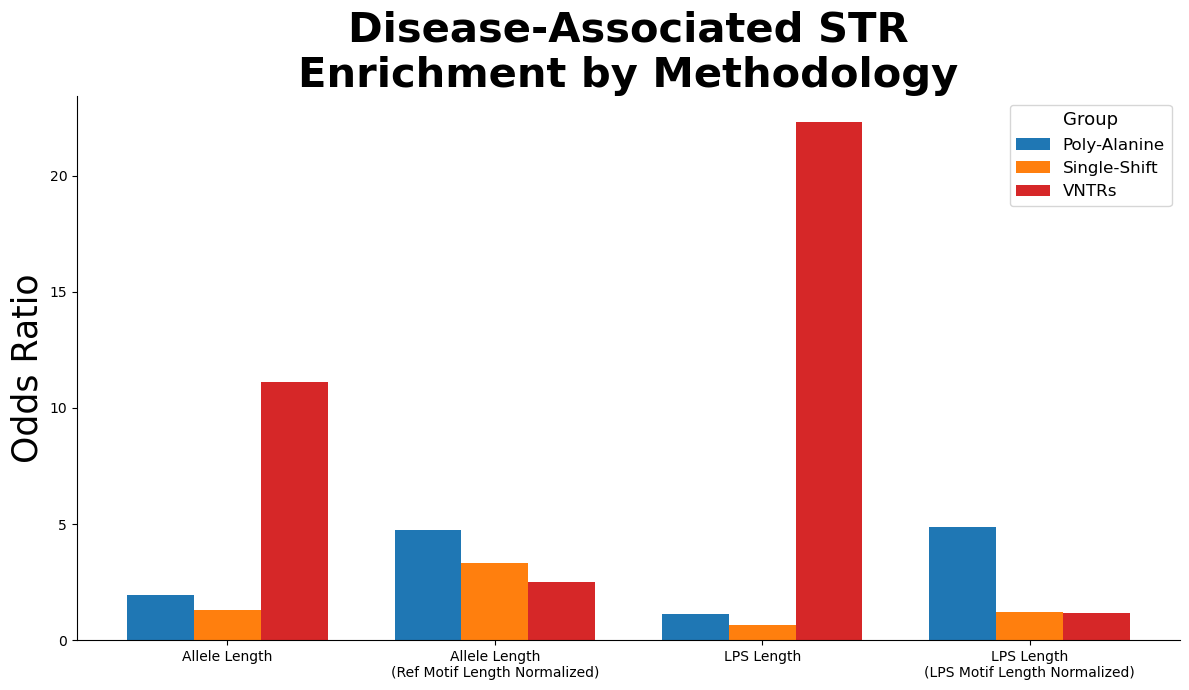

In [ ]:
# Grouped bar plot for S7C: odds ratios by group and methodology
import matplotlib.ticker as mticker

# Odds ratios extracted from the analyses above
odds_ratios = {
    'Poly-Alanine':  [1.9628, 4.7348, 1.1162, 4.8510],
    'Single-Shift':  [1.2998, 3.3234, 0.6613, 1.2102],
    'VNTRs':         [11.1084, 2.5207, 22.3170, 1.1712],
}
categoryNames = [
    'Allele Length',
    'Allele Length\n(Ref Motif Length Normalized)',
    'LPS Length',
    'LPS Length\n(LPS Motif Length Normalized)',
]
groupNames = list(odds_ratios.keys())

mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['svg.fonttype'] = 'none'
fig, ax = plt.subplots(figsize=(12, 7))

x = np.arange(len(categoryNames))
n_groups = len(groupNames)
width = 0.25
offsets = np.linspace(-(n_groups - 1) * width / 2, (n_groups - 1) * width / 2, n_groups)

colors = plt.cm.tab10(np.linspace(0, 0.3, n_groups))
for idx, group in enumerate(groupNames):
    ax.bar(x + offsets[idx], odds_ratios[group], width, label=group, color=colors[idx])

ax.set_ylabel('Odds Ratio', fontsize=25)
ax.set_title('Disease-Associated STR\nEnrichment by Methodology', fontsize=30, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(categoryNames)
#plt.yscale('log')
ax.yaxis.set_major_formatter(mticker.ScalarFormatter())
ax.yaxis.set_minor_formatter(mticker.ScalarFormatter())
ax.ticklabel_format(axis='y', style='plain')
ax.legend(title='Group', fontsize=12, title_fontsize=13)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('figures/SupplementaryFigure7C.svg')
plt.savefig('figures/SupplementaryFigure7C.png', dpi=600)


# S8: Supplementary Linkage Region Plots

C:\Users\Matt\AppData\Local\Temp\ipykernel_72752\418685781.py:148: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  result_df = pd.concat([result_df, new_row], ignore_index=True)


HTT: Rank 1/4232, Value: 1.0000
C9orf72: Rank 23/17497, Value: 0.9987
THAP11: Rank 224/14334, Value: 0.9844
ZFHX3: Rank 186/14334, Value: 0.9871
FGF14: Rank 1/2139, Value: 1.0000
ATXN10: Rank 1/5591, Value: 1.0000
THAP11: Rank 172/11683, Value: 0.9854
BEAN1: Rank 2/11683, Value: 0.9999
DAB1: Rank 2/3334, Value: 0.9997
FXN: Rank 2/4742, Value: 0.9998
STARD7: Rank 19/25124, Value: 0.9993
AFF3: Rank 4/25124, Value: 0.9999
MARCHF6: Rank 296/13650, Value: 0.9784
ABCD3: Rank 185/61228, Value: 0.9970
NOTCH2NLC: Rank 15/61228, Value: 0.9998
CNBP: Rank 1/14233, Value: 1.0000


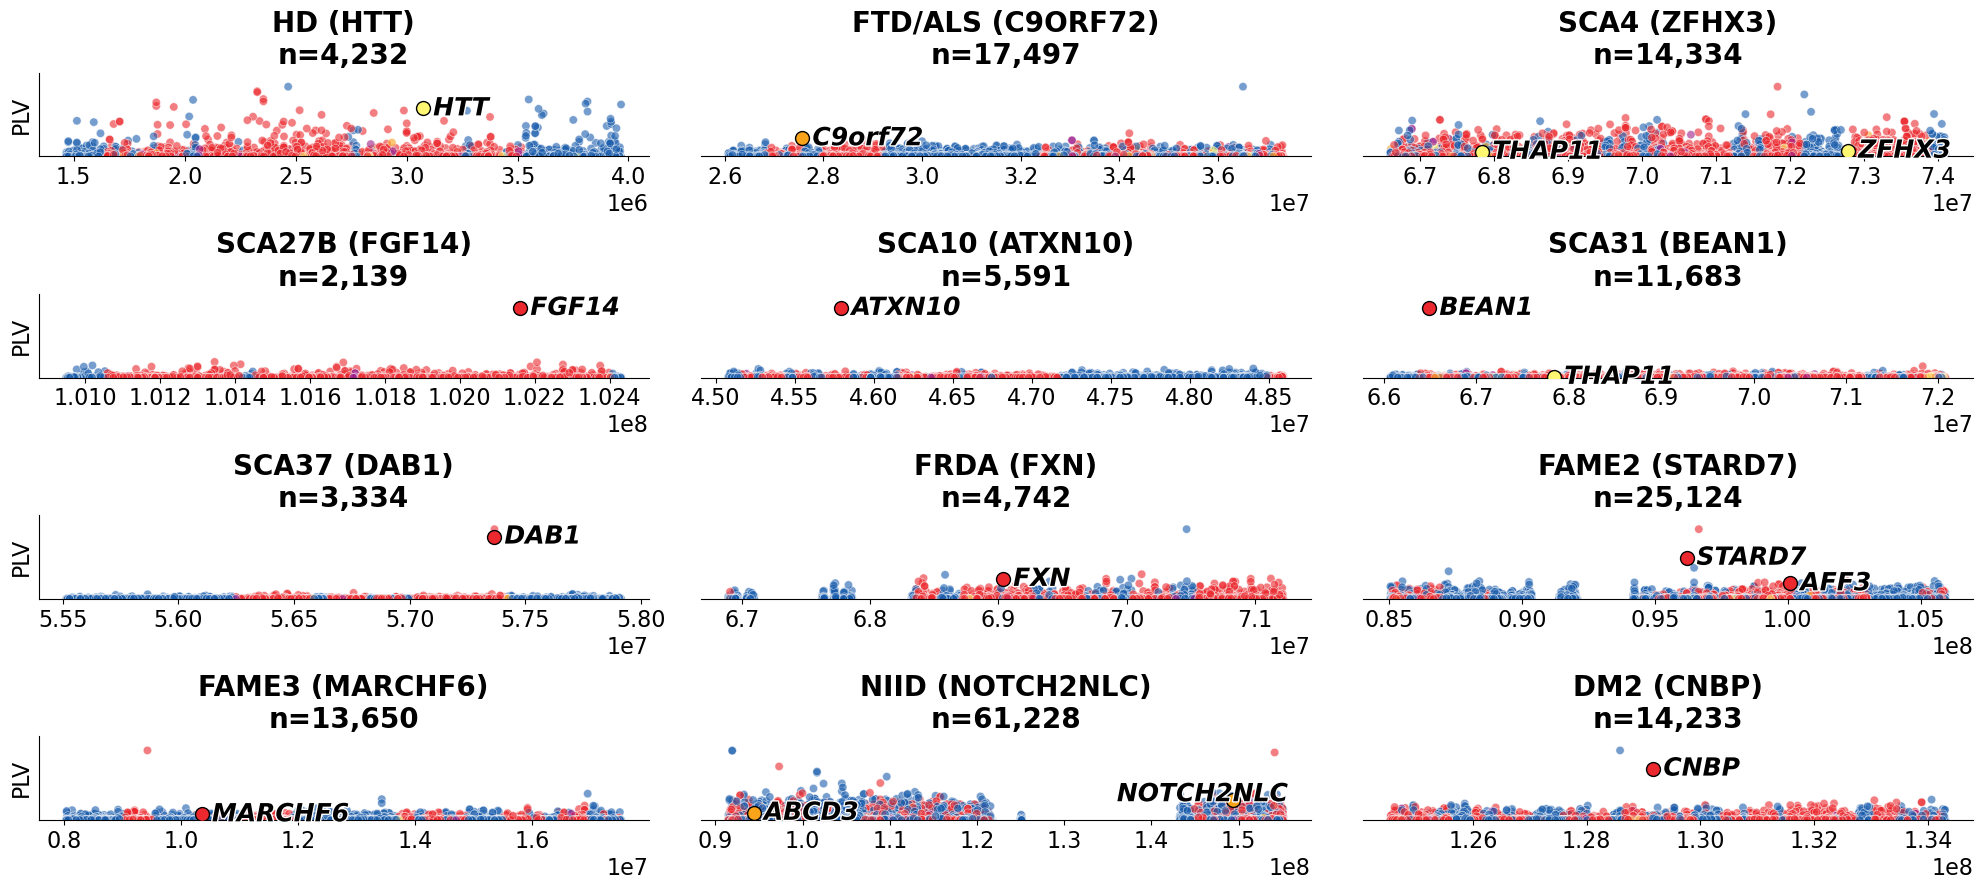

In [23]:

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sb
import matplotlib.patheffects as pe

mpl.rcParams['svg.fonttype'] = 'none'  # keep SVG text in SVGs

df=pd.read_csv('statsTables/DiscoveryCohort_lpsPerMotifStats.TR_Explorer_1.0.1.txt.gz', sep="\t")

# rescue CNBP
df=df.loc[~((df['TRID']=='3-129172576-129172656-CAGG,3-129172656-129172696-CAGA,3-129172691-129172693-AC,3-129172696-129172732-CA') & (df['LPS_Motif'].isin(['AC','ACAG']))),:]

# drop to the most common LPS motif per locus
df=df.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)

genicAnnotations=pd.read_csv('assets/genicRegionAnnotations_TRExplorer.txt.gz',sep='\t',header=None,names=['TRID','region'])
df=df.merge(genicAnnotations,how='left',on='TRID')
df.loc[df['region'].isna(),'region']='intergenic'
# function to convert motifs to their simplest rotational form
def simplest_motif(motif):
    i = (motif+motif).find(motif, 1, -1)
    if i != -1:
        motif = motif[:i]
    motifs = []
    b = len(motif)
    for i in range(b):
        c = motif[i:]+motif[:i]
        motifs.append(c)
    motifs = [x.upper() for x in motifs]   
    return(min(motifs))

# apply the simplest_motif function the data
df['simpleMotif']=df.loc[:,'LPS_Motif'].apply(simplest_motif)
df['motifLen']=df.loc[:,'simpleMotif'].str.len()
# calculate percentile of standard deviation within each motif grouping
df['percentile_stdev']=df.groupby('motifLen',observed=True)['std'].rank(pct=True)

# drop to just the STRs
df=df.loc[df['simpleMotif'].str.len()<=6,:].reset_index(drop=True)

# Define pathogenic TRIDs
pathogenic=pd.read_csv('assets/pathogenicTRIDs_TRExplorer_v1.0.1_STRchiveFiltered_noVNTRs_withAnno.txt',sep='\t')
df=df.merge(pathogenic.loc[:,['TRID','geneName']],how='left',on='TRID').rename(columns={'geneName':'gene'})
df['Status'] = 'Catalog'
df.loc[~(df['gene'].isna()), 'Status'] = 'Pathogenic'

# Panel definitions (phenotype regions)
regions = [
    'HD chr4_1467045_3967045', 'FTD/ALS chr9_26071033_37322562',
    'SCA4 chr16_66600001_74100000', 'SCA27B chr13_100949908_102431199',
    'SCA10 chr22_45079539_48590066', 'SCA31 chr16_66067491_72076730', 
    'SCA37 chr1_55515300_57914975', 'FRDA chr9_66891164_71223663',
    'FAME2 chr2_85059961_105930167', 'FAME3 chr5_8040420_17547546', 
    'NIID chr1_91500001_155100000', 'DM2 chr3_124549644_134304744'
]

regionsLabels = [
    'HD (HTT)\nn=4,232', 'FTD/ALS (C9ORF72)\nn=17,497', 
    'SCA4 (ZFHX3)\nn=14,334', 'SCA27B (FGF14)\nn=2,139', 'SCA10 (ATXN10)\nn=5,591', 'SCA31 (BEAN1)\nn=11,683',
    'SCA37 (DAB1)\nn=3,334', 'FRDA (FXN)\nn=4,742', 'FAME2 (STARD7)\nn=25,124',
    'FAME3 (MARCHF6)\nn=13,650', 'NIID (NOTCH2NLC)\nn=61,228', 'DM2 (CNBP)\nn=14,233'
]

# Category → color mapping
regs = ['intron', 'intergenic', 'UTR_3', 'UTR_5', 'coding']
cols = ['#EB282D', '#195CAC', '#9D1E89', '#F9A31B', '#FFF672']
cm = dict(zip(regs, cols))

# Container for per-panel results (rank/percentile summaries)
result_df = pd.DataFrame(columns=['regionSize','pheno','gene','motif','rank','nTRs','percentile'])

# Plot grid (4 rows × 3 cols = 12 panels)
fig, axs = plt.subplots(nrows=4, ncols=3, figsize=(20, 9))
axs = np.atleast_2d(axs)

### Panel loop
for idx, region in enumerate(regions):
    row = idx // 3
    col = idx % 3

    pheno, coords = region.split(' ')
    chrom, start, end = coords.split('_')
    chrom=chrom[3:]
    start = int(start); end = int(end)
    length = end - start
    lab = regionsLabels[idx]

    d = df[df['TRID'].str.startswith(chrom + '-')].copy()
    d[['chr', 'start', 'end','motif']] = d['TRID'].str.split(',', expand=True).iloc[:,0].str.split('-',expand=True)
    d['start'] = d['start'].astype(int)
    d['end'] = d['end'].astype(int)
    d = d[(d['start'] > start) & (d['end'] < end)].copy()

    d = d[d['percentile_stdev'].notna()].copy()
    d = d.sample(frac=1, random_state=7)  # shuffle to avoid patterning

    # region-specific tweak (kept from original): reclassify some exon calls in SCA4
    if region == 'SCA4 chr16_66600001_74100000':
        mask_non3 = (d['region'] == 'coding') & (d['simpleMotif'].str.len() % 3 != 0)
        d.loc[mask_non3, 'region'] = 'intron'

    # scatter
    ax = axs[row, col]
    sb.scatterplot(
        x=d['start'], y=d['std'], hue=d['region'], palette=cm,
        ax=ax, marker='o', alpha=0.6, rasterized=True, legend=False
    )

    # Only show y-axis for the leftmost subplot (col == 0)
    if col == 0:
        ax.set_ylabel('PLV', fontsize=16)
        ax.set_yticks([])
    else:
        ax.set_yticks([])
        ax.set_ylabel('')
        ax.spines['left'].set_visible(False)

    if len(d) and d['std'].max() > 0:
        ax.set_ylim(0, d['std'].max() * 1.2)
    ax.set_xlabel('')
    ax.tick_params(labelsize=16)
    ax.xaxis.get_offset_text().set_fontsize(16)
    ax.set_title(lab, fontsize=20, fontweight='bold')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    total_TRs = len(d)
    if total_TRs:
        d = d.sort_values('percentile_stdev', ascending=True).copy()
        d['Stdev_rank'] = d['percentile_stdev'].rank(ascending=False)

        # annotate pathogenic points and collect ranks
        for _, point in d.iterrows():
            if point.get('Status') == 'Pathogenic':
                percentile_value = 1 - ((point['Stdev_rank'] - 1) / total_TRs)
                new_row = pd.DataFrame({
                    'regionSize': [length],
                    'pheno': [pheno],
                    'gene': [point['gene']],
                    'motif': [point['simpleMotif']],
                    'rank': [int(point['Stdev_rank'])],
                    'nTRs': [total_TRs],
                    'percentile': [percentile_value]
                })
                result_df = pd.concat([result_df, new_row], ignore_index=True)
                print(f"{point['gene']}: Rank {int(point['Stdev_rank'])}/{total_TRs}, Value: {percentile_value:.4f}")

                ax.scatter(point['start'], point['std'],
                           marker='o', color=cm.get(point['region'], 'red'),
                           edgecolors='black', s=100, zorder=3)

                if point['gene'] != 'NOTCH2NLC':
                    ax.annotate(
                        f"{point['gene']}",
                        (point['start'] + (length * 0.018), point['std']),
                        fontsize=18,
                        path_effects=[pe.withStroke(linewidth=2, foreground='white')],
                        color='black', fontstyle='italic', fontweight='bold',
                        ha='left', va='center'
                    )
                else:
                    ax.annotate(
                        f"{point['gene']}",
                        (point['start'] - (length * 0.21), point['std'] + 4),
                        fontsize=18,
                        path_effects=[pe.withStroke(linewidth=2, foreground='white')],
                        color='black', fontstyle='italic', fontweight='bold',
                        ha='left', va='center'
                    )
plt.tight_layout()
plt.savefig('figures/SupplementaryFigure8.svg')
plt.savefig('figures/SupplementaryFigure8.png',dpi=600)

# S9: Outliers per Sample

## S9A

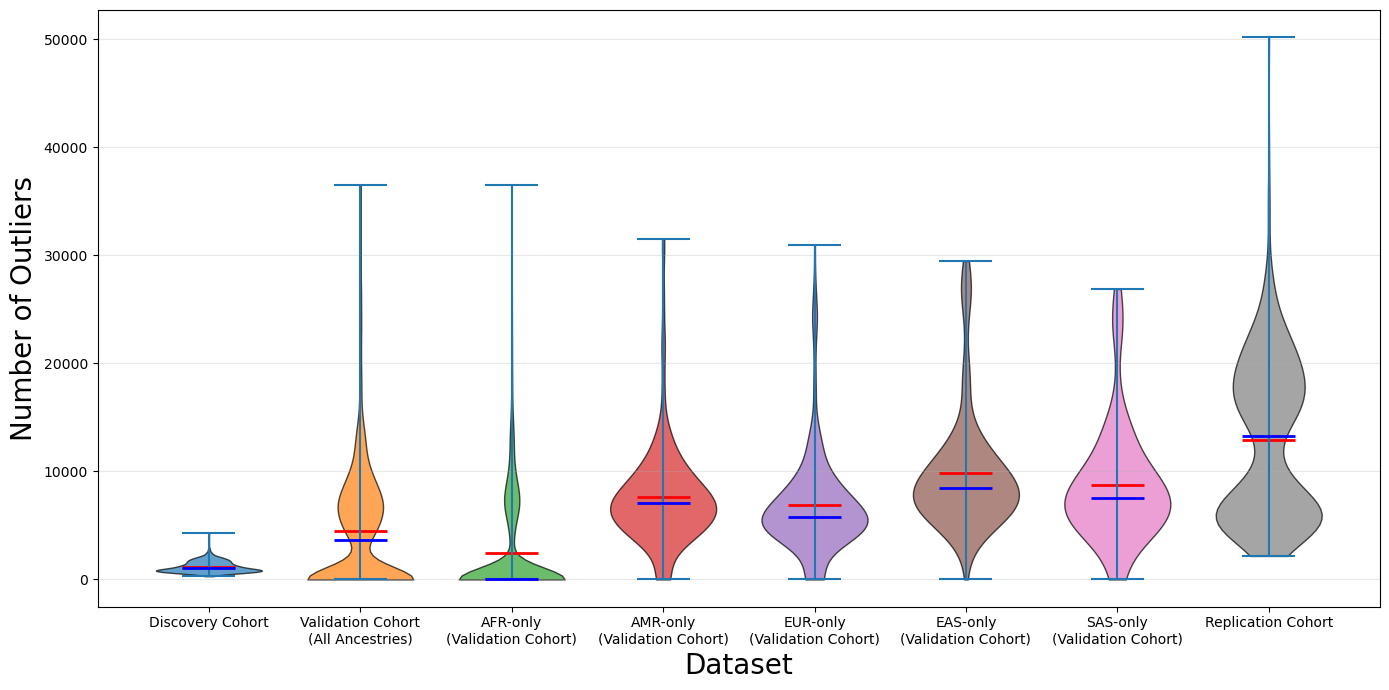


=== Summary Statistics for 99.9th Percentile Outliers ===

Discovery Cohort:
  Mean: 1172.61
  Median: 1032.00
  Std Dev: 510.24
  Min: 294.00
  Max: 4296.00
  N samples: 544

Validation Cohort
(All Ancestries):
  Mean: 4453.89
  Median: 3654.00
  Std Dev: 5439.67
  Min: 0.00
  Max: 36522.00
  N samples: 2129

AFR-only
(Validation Cohort):
  Mean: 2425.83
  Median: 0.00
  Std Dev: 4605.24
  Min: 0.00
  Max: 36522.00
  N samples: 1324

AMR-only
(Validation Cohort):
  Mean: 7642.18
  Median: 7090.50
  Std Dev: 4711.66
  Min: 0.00
  Max: 31481.00
  N samples: 290

EUR-only
(Validation Cohort):
  Mean: 6887.20
  Median: 5738.00
  Std Dev: 4842.92
  Min: 0.00
  Max: 30907.00
  N samples: 296

EAS-only
(Validation Cohort):
  Mean: 9894.74
  Median: 8464.00
  Std Dev: 5523.02
  Min: 0.00
  Max: 29463.00
  N samples: 123

SAS-only
(Validation Cohort):
  Mean: 8700.60
  Median: 7566.00
  Std Dev: 5436.84
  Min: 0.00
  Max: 26885.00
  N samples: 78

Replication Cohort:
  Mean: 12863.54
  Median

In [1]:
# initial data loading and package import
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sb
from matplotlib.colors import to_rgba

mpl.rcParams['svg.fonttype'] = 'none'  # keep SVG text in SVGs

highCovComplete=pd.read_csv('assets/outlierAnalyses/DiscoveryCohort_AlleleLengthOutliersPerSample.txt',sep='\t')
lowCovComplete=pd.read_csv('assets/outlierAnalyses/ValidationCohort_AlleleLengthOutliersPerSample.txt',sep='\t')
AFR=pd.read_csv('assets/outlierAnalyses/ValidationCohort_AlleleLengthOutliersPerSample_AFR.txt',sep='\t')
AMR=pd.read_csv('assets/outlierAnalyses/ValidationCohort_AlleleLengthOutliersPerSample_AMR.txt',sep='\t')
EUR=pd.read_csv('assets/outlierAnalyses/ValidationCohort_AlleleLengthOutliersPerSample_EUR.txt',sep='\t')
EAS=pd.read_csv('assets/outlierAnalyses/ValidationCohort_AlleleLengthOutliersPerSample_EAS.txt',sep='\t')
SAS=pd.read_csv('assets/outlierAnalyses/ValidationCohort_AlleleLengthOutliersPerSample_SAS.txt',sep='\t')
ONT=pd.read_csv('assets/outlierAnalyses/ReplicationCohort_AlleleLengthOutliersPerSample.txt',sep='\t')

# Create violin plot for 99.9th Percentile across populations
datasets = {
    'Discovery Cohort': highCovComplete,
    'Validation Cohort\n(All Ancestries)': lowCovComplete,
    'AFR-only\n(Validation Cohort)': AFR,
    'AMR-only\n(Validation Cohort)': AMR,
    'EUR-only\n(Validation Cohort)': EUR,
    'EAS-only\n(Validation Cohort)': EAS,
    'SAS-only\n(Validation Cohort)': SAS,
    'Replication Cohort': ONT
}

# Collect data for violin plot
plot_data = []
for dataset_name, dataset in datasets.items():
    if '99.9thPercentile' in dataset.columns:
        values = dataset['99.9thPercentile'].dropna()
        for val in values:
            plot_data.append({
                'Dataset': dataset_name,
                'Value': val
            })

plot_df = pd.DataFrame(plot_data)

# Create violin plot
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['svg.fonttype'] = 'none'
fig, ax = plt.subplots(figsize=(14, 7))

# Get colors matching the existing plot style
colors = plt.cm.tab10(np.linspace(0, 0.7, len(datasets)))
color_palette = [plt.cm.tab10(i/9) for i in range(len(datasets))]

# Create violin plot using seaborn
parts = ax.violinplot(
    [plot_df[plot_df['Dataset'] == name]['Value'].values for name in datasets.keys()],
    positions=range(len(datasets)),
    widths=0.7,
    showmeans=True,
    showmedians=True
)

# Color the violin plots
for idx, pc in enumerate(parts['bodies']):
    pc.set_facecolor(color_palette[idx])
    pc.set_alpha(0.7)
    pc.set_edgecolor('black')
    pc.set_linewidth(1)

# Customize other elements
parts['cmeans'].set_color('red')
parts['cmeans'].set_linewidth(2)
parts['cmedians'].set_color('blue')
parts['cmedians'].set_linewidth(2)

# Set labels and title
ax.set_xticks(range(len(datasets)))
ax.set_xticklabels(datasets.keys(), rotation=0, fontsize=10)
ax.set_ylabel('Number of Outliers', fontsize=20)
ax.set_xlabel('Dataset', fontsize=20)
#ax.set_title('Distribution of Allele Length Outliers (99.9th Percentile) Across Populations', 
#             fontsize=14, fontweight='bold')
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('figures/SupplementaryFigure9A.png',dpi=600)
plt.savefig('figures/SupplementaryFigure9A.svg')
plt.show()

# Print summary statistics
print("\n=== Summary Statistics for 99.9th Percentile Outliers ===")
for dataset_name, dataset in datasets.items():
    if '99.9thPercentile' in dataset.columns:
        values = dataset['99.9thPercentile'].dropna()
        print(f"\n{dataset_name}:")
        print(f"  Mean: {values.mean():.2f}")
        print(f"  Median: {values.median():.2f}")
        print(f"  Std Dev: {values.std():.2f}")
        print(f"  Min: {values.min():.2f}")
        print(f"  Max: {values.max():.2f}")
        print(f"  N samples: {len(values)}")


## S9B

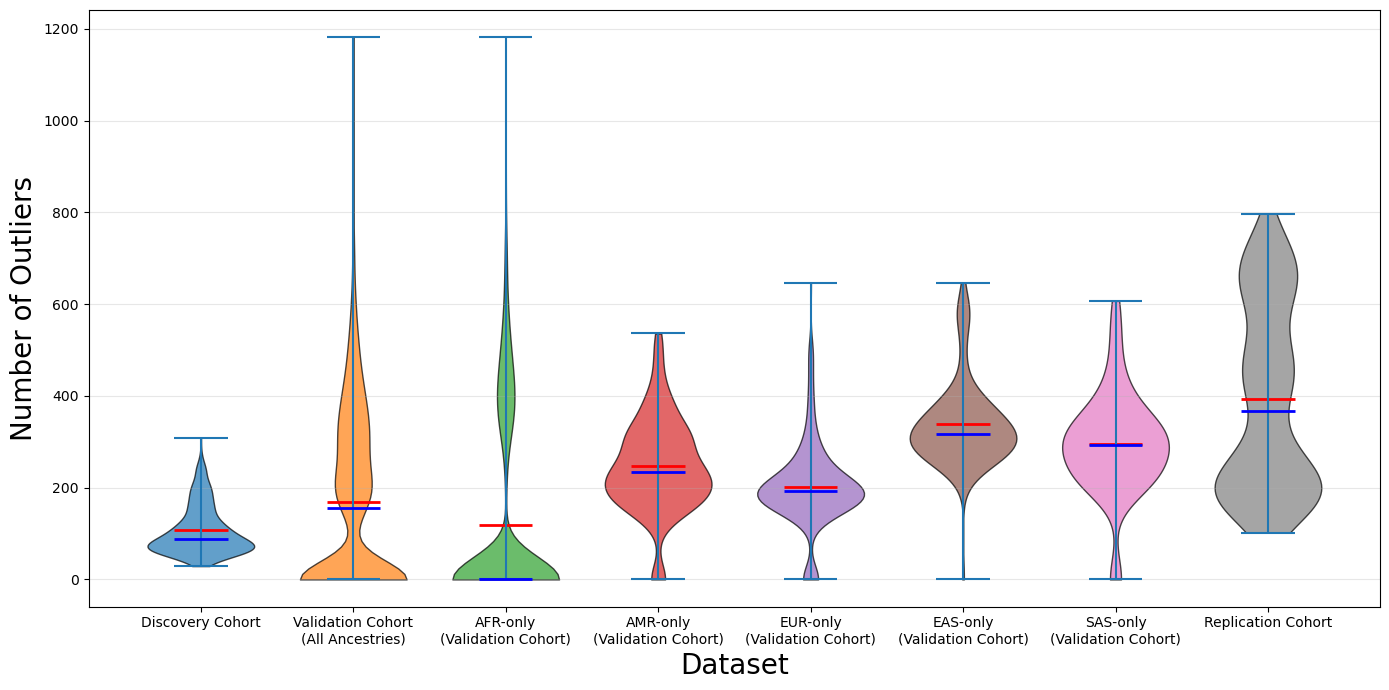


=== Summary Statistics for 99.9th Percentile Outliers ===

Discovery Cohort:
  Mean: 106.86
  Median: 89.00
  Std Dev: 52.83
  Min: 29.00
  Max: 309.00
  N samples: 544

Validation Cohort
(All Ancestries):
  Mean: 168.33
  Median: 155.00
  Std Dev: 188.04
  Min: 0.00
  Max: 1182.00
  N samples: 2129

AFR-only
(Validation Cohort):
  Mean: 118.94
  Median: 0.00
  Std Dev: 207.03
  Min: 0.00
  Max: 1182.00
  N samples: 1324

AMR-only
(Validation Cohort):
  Mean: 246.83
  Median: 233.50
  Std Dev: 103.24
  Min: 0.00
  Max: 536.00
  N samples: 290

EUR-only
(Validation Cohort):
  Mean: 202.33
  Median: 192.00
  Std Dev: 94.55
  Min: 0.00
  Max: 646.00
  N samples: 296

EAS-only
(Validation Cohort):
  Mean: 338.50
  Median: 318.00
  Std Dev: 93.51
  Min: 0.00
  Max: 647.00
  N samples: 123

SAS-only
(Validation Cohort):
  Mean: 295.09
  Median: 293.50
  Std Dev: 113.76
  Min: 0.00
  Max: 607.00
  N samples: 78

Replication Cohort:
  Mean: 392.76
  Median: 366.00
  Std Dev: 204.46
  Min: 102

In [2]:
# initial data loading and package import
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sb
from matplotlib.colors import to_rgba

mpl.rcParams['svg.fonttype'] = 'none'  # keep SVG text in SVGs

highCovComplete=pd.read_csv('assets/outlierAnalyses/DiscoveryCohort_LPSOutliersPerSample_top5Percent.txt',sep='\t')
lowCovComplete=pd.read_csv('assets/outlierAnalyses/ValidationCohort_LPSOutliersPerSample_top5Percent.txt',sep='\t')
AFR=pd.read_csv('assets/outlierAnalyses/ValidationCohort_LPSOutliersPerSample_AFR_top5Percent.txt',sep='\t')
AMR=pd.read_csv('assets/outlierAnalyses/ValidationCohort_LPSOutliersPerSample_AMR_top5Percent.txt',sep='\t')
EUR=pd.read_csv('assets/outlierAnalyses/ValidationCohort_LPSOutliersPerSample_EUR_top5Percent.txt',sep='\t')
EAS=pd.read_csv('assets/outlierAnalyses/ValidationCohort_LPSOutliersPerSample_EAS_top5Percent.txt',sep='\t')
SAS=pd.read_csv('assets/outlierAnalyses/ValidationCohort_LPSOutliersPerSample_SAS_top5Percent.txt',sep='\t')
ONT=pd.read_csv('assets/outlierAnalyses/ReplicationCohort_LPSOutliersPerSample_top5Percent.txt',sep='\t')

# Create violin plot for 99.9th Percentile across populations that is also filtered for top 5% most variable loci
datasets = {
    'Discovery Cohort': highCovComplete,
    'Validation Cohort\n(All Ancestries)': lowCovComplete,
    'AFR-only\n(Validation Cohort)': AFR,
    'AMR-only\n(Validation Cohort)': AMR,
    'EUR-only\n(Validation Cohort)': EUR,
    'EAS-only\n(Validation Cohort)': EAS,
    'SAS-only\n(Validation Cohort)': SAS,
    'Replication Cohort': ONT
}

# Collect data for violin plot
plot_data = []
for dataset_name, dataset in datasets.items():
    if '99.9thPercentile' in dataset.columns:
        values = dataset['99.9thPercentile'].dropna()
        for val in values:
            plot_data.append({
                'Dataset': dataset_name,
                'Value': val
            })

plot_df = pd.DataFrame(plot_data)

# Create violin plot
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['svg.fonttype'] = 'none'
fig, ax = plt.subplots(figsize=(14, 7))

# Get colors matching the existing plot style
colors = plt.cm.tab10(np.linspace(0, 0.7, len(datasets)))
color_palette = [plt.cm.tab10(i/9) for i in range(len(datasets))]

# Create violin plot using seaborn
parts = ax.violinplot(
    [plot_df[plot_df['Dataset'] == name]['Value'].values for name in datasets.keys()],
    positions=range(len(datasets)),
    widths=0.7,
    showmeans=True,
    showmedians=True
)

# Color the violin plots
for idx, pc in enumerate(parts['bodies']):
    pc.set_facecolor(color_palette[idx])
    pc.set_alpha(0.7)
    pc.set_edgecolor('black')
    pc.set_linewidth(1)

# Customize other elements
parts['cmeans'].set_color('red')
parts['cmeans'].set_linewidth(2)
parts['cmedians'].set_color('blue')
parts['cmedians'].set_linewidth(2)

# Set labels and title
ax.set_xticks(range(len(datasets)))
ax.set_xticklabels(datasets.keys(), rotation=0, fontsize=10)
ax.set_ylabel('Number of Outliers', fontsize=20)
ax.set_xlabel('Dataset', fontsize=20)
#ax.set_title('Distribution of Allele LPS and Variation Outliers Across Populations', 
#             fontsize=14, fontweight='bold')
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('figures/SupplementaryFigure9B.png',dpi=600)
plt.savefig('figures/SupplementaryFigure9B.svg')
plt.show()

# Print summary statistics
print("\n=== Summary Statistics for 99.9th Percentile Outliers ===")
for dataset_name, dataset in datasets.items():
    if '99.9thPercentile' in dataset.columns:
        values = dataset['99.9thPercentile'].dropna()
        print(f"\n{dataset_name}:")
        print(f"  Mean: {values.mean():.2f}")
        print(f"  Median: {values.median():.2f}")
        print(f"  Std Dev: {values.std():.2f}")
        print(f"  Min: {values.min():.2f}")
        print(f"  Max: {values.max():.2f}")
        print(f"  N samples: {len(values)}")



# S10: Swimlane Plots (Supplementary results)

## S10A

In [ ]:
%%bash
# SCA27B Case using HiFi data
SAMPLEID="SCA27B_case"
repeat_catalog_nickname="TR-Explorer_v1.0.1"
repeat_catalog_nickname2="TR-Explorer_v1.0.1_AoUPhase1"
catalog_lps_stats="DiscoveryCohort_lpsPerMotifStats_trgt.TR_Explorer_1.0.1.txt.gz"
pathogenicTRID="13-102161566-102161579-AAGA,13-102161574-102161724-AAG,13-102161829-102161844-A"
bcftools query -f "${SAMPLEID}\t%INFO/TRID\t%INFO/MOTIFS\t[%TGT\t%AL{0}\t%AL{1}\t%SD{0}\t%SD{1}\t%AM{0}\t%AM{1}]" ${SAMPLEID}_${repeat_catalog_nickname}_trgt.vcf.gz > ${SAMPLEID}_${repeat_catalog_nickname}_trgt.txt
python scripts/prioritizeTRWithinSample.py --inputFile=${SAMPLEID}_${repeat_catalog_nickname}_trgt.txt --sampleID=${SAMPLEID} --comparisonCatalog=${catalog_lps_stats} --comparisonCatalogNickname=${repeat_catalog_nickname2} --pathogenicTRID=${pathogenicTRID}

c:\Users\Matt\anaconda3\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Matt\anaconda3\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Matt\anaconda3\lib\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


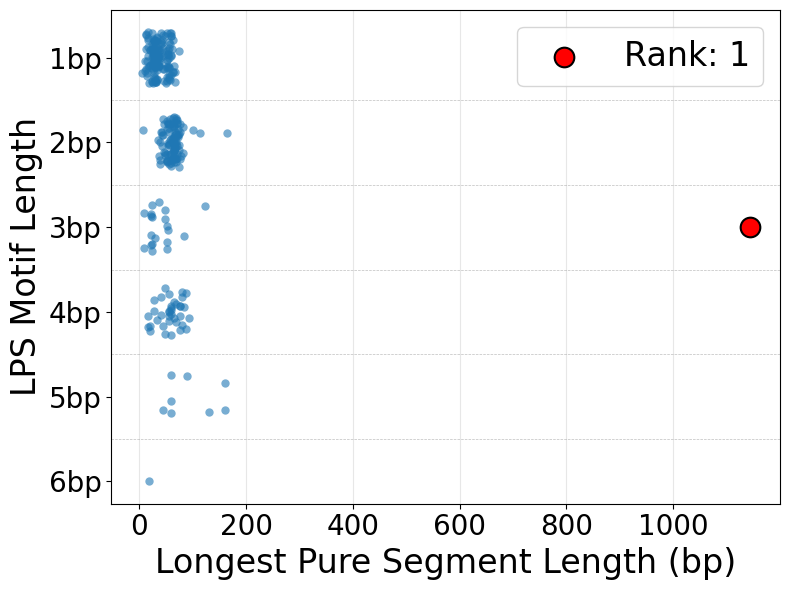

In [6]:
# re-draw plot using a red circle
import pandas as pd
ranked=pd.read_csv('assets/outlierAnalyses/FGF14_case1/SCA27B_Case_trgt.TR-Explorer_v1.0.1_AoUPhase1_prioritized_ranks.txt',sep='\t')
pathogenicTRID="13-102161566-102161579-AAGA,13-102161574-102161724-AAG,13-102161829-102161844-A"
sampleID="SCA27B_case"
# Create the swimlane plot
import matplotlib as mpl
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 6))

# Define motif categories
motif_categories = ['1bp', '2bp', '3bp', '4bp', '5bp', '6bp']
ranked=ranked.loc[ranked['Motif_Length_Category'].isin(motif_categories),:].reset_index(drop=True)

# get rank of pathogenic variant
overall_rank=ranked[ranked['TRID'] == pathogenicTRID].index.values[0]+1

# Create stripplot with categories
pathogenic_data = ranked[ranked['TRID'] == pathogenicTRID]
# drop the pathogenic entry from sample4_sorted
ranked2 = ranked[ranked['TRID'] != pathogenicTRID]
sns.stripplot(data=ranked2,
            y='Motif_Length_Category',
            x='LPS_Length',
            order=motif_categories,
            alpha=0.6,
            size=6,
            jitter=0.3)

# Add thin dashed grey lines between strips
for i in range(len(motif_categories) - 1):
    plt.axhline(y=i + 0.5, color='grey', linestyle='--', linewidth=0.5, alpha=0.5)

# Highlight the pathogenic TRID if found
plt.scatter(pathogenic_data['LPS_Length'],
            pathogenic_data['Motif_Length_Category'],
            color='red',
            s=200,
            marker='o',
            zorder=5,
            label=f'Rank: {overall_rank}',
            edgecolors='black',
            linewidths=1.5)

plt.xlabel('Longest Pure Segment Length (bp)', fontsize=24)
plt.ylabel('LPS Motif Length', fontsize=24)
plt.tick_params(labelsize=20)
plt.legend(loc='upper right',fontsize=24)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()

# Save the plot
plt.savefig("figures/SupplementaryFigure10A.png", dpi=600, bbox_inches='tight')
plt.savefig("figures/SupplementaryFigure10A.svg", bbox_inches='tight')


## S10B

In [ ]:
%%bash
# SCA27B Case 2 using HiFi data
SAMPLEID="SCA27B_case2"
repeat_catalog_nickname="TR-Explorer_v1.0.1"
repeat_catalog_nickname2="TR-Explorer_v1.0.1_AoUPhase1"
catalog_lps_stats="DiscoveryCohort_lpsPerMotifStats_trgt.TR_Explorer_1.0.1.txt.gz"
pathogenicTRID="13-102161566-102161579-AAGA,13-102161574-102161724-AAG,13-102161829-102161844-A"
bcftools query -f "${SAMPLEID}\t%INFO/TRID\t%INFO/MOTIFS\t[%TGT\t%AL{0}\t%AL{1}\t%SD{0}\t%SD{1}\t%AM{0}\t%AM{1}]" ${SAMPLEID}_${repeat_catalog_nickname}_trgt.vcf.gz > ${SAMPLEID}_${repeat_catalog_nickname}_trgt.txt
python scripts/prioritizeTRWithinSample.py --inputFile=${SAMPLEID}_${repeat_catalog_nickname}_trgt.txt --sampleID=${SAMPLEID} --comparisonCatalog=${catalog_lps_stats} --comparisonCatalogNickname=${repeat_catalog_nickname2} --pathogenicTRID=${pathogenicTRID}


c:\Users\Matt\anaconda3\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Matt\anaconda3\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Matt\anaconda3\lib\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


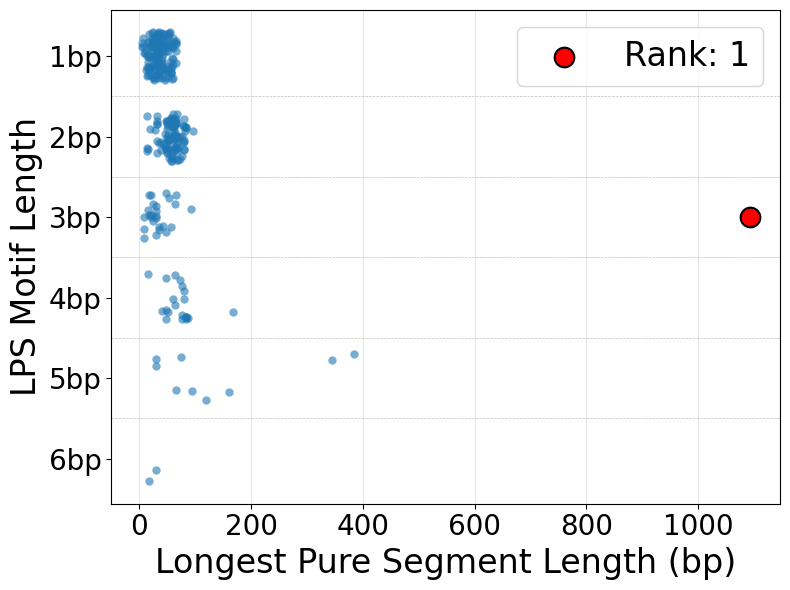

In [7]:
# re-draw plot using a red circle
import pandas as pd
ranked=pd.read_csv('assets/outlierAnalyses/FGF14_case2/SCA27B_Case2_trgt.TR-Explorer_v1.0.1_AoUPhase1_prioritized_ranks.txt',sep='\t')
pathogenicTRID="13-102161566-102161579-AAGA,13-102161574-102161724-AAG,13-102161829-102161844-A"
sampleID="SCA27B_case2"

# Create the swimlane plot
import matplotlib as mpl
import seaborn as sns
plt.figure(figsize=(8, 6))

# Define motif categories
motif_categories = ['1bp', '2bp', '3bp', '4bp', '5bp', '6bp']
ranked=ranked.loc[ranked['Motif_Length_Category'].isin(motif_categories),:].reset_index(drop=True)

# get rank of pathogenic variant
overall_rank=ranked[ranked['TRID'] == pathogenicTRID].index.values[0]+1

# Create stripplot with categories
pathogenic_data = ranked[ranked['TRID'] == pathogenicTRID]
# drop the pathogenic entry from sample4_sorted
ranked2 = ranked[ranked['TRID'] != pathogenicTRID]
sns.stripplot(data=ranked2,
            y='Motif_Length_Category',
            x='LPS_Length',
            order=motif_categories,
            alpha=0.6,
            size=6,
            jitter=0.3)

# Add thin dashed grey lines between strips
for i in range(len(motif_categories) - 1):
    plt.axhline(y=i + 0.5, color='grey', linestyle='--', linewidth=0.5, alpha=0.5)

# Highlight the pathogenic TRID if found
plt.scatter(pathogenic_data['LPS_Length'],
            pathogenic_data['Motif_Length_Category'],
            color='red',
            s=200,
            marker='o',
            zorder=5,
            label=f'Rank: {overall_rank}',
            edgecolors='black',
            linewidths=1.5)

plt.xlabel('Longest Pure Segment Length (bp)', fontsize=24)
plt.ylabel('LPS Motif Length', fontsize=24)
plt.tick_params(labelsize=20)
plt.legend(loc='upper right',fontsize=24)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()

# Save the plot
plt.savefig("figures/SupplementaryFigure10B.png", dpi=600, bbox_inches='tight')
plt.savefig("figures/SupplementaryFigure10B.svg", bbox_inches='tight')


## S10C

In [ ]:
%%bash
# ATXN2 Case using HiFi data
SAMPLEID="ATXN2_case"
repeat_catalog_nickname="TR-Explorer_v1.0.1"
repeat_catalog_nickname2="TR-Explorer_v1.0.1_AoUPhase1"
catalog_lps_stats="DiscoveryCohort_lpsPerMotifStats_trgt.TR_Explorer_1.0.1.txt.gz"
pathogenicTRID="12-111598949-111599018-GCT"
bcftools query -f "${SAMPLEID}\t%INFO/TRID\t%INFO/MOTIFS\t[%TGT\t%AL{0}\t%AL{1}\t%SD{0}\t%SD{1}\t%AM{0}\t%AM{1}]" ${SAMPLEID}_${repeat_catalog_nickname}_trgt.vcf.gz > ${SAMPLEID}_${repeat_catalog_nickname}_trgt.txt
python scripts/prioritizeTRWithinSample.py --inputFile=${SAMPLEID}_${repeat_catalog_nickname}_trgt.txt --sampleID=${SAMPLEID} --comparisonCatalog=${catalog_lps_stats} --comparisonCatalogNickname=${repeat_catalog_nickname2} --pathogenicTRID=${pathogenicTRID}


c:\Users\Matt\anaconda3\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Matt\anaconda3\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Matt\anaconda3\lib\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


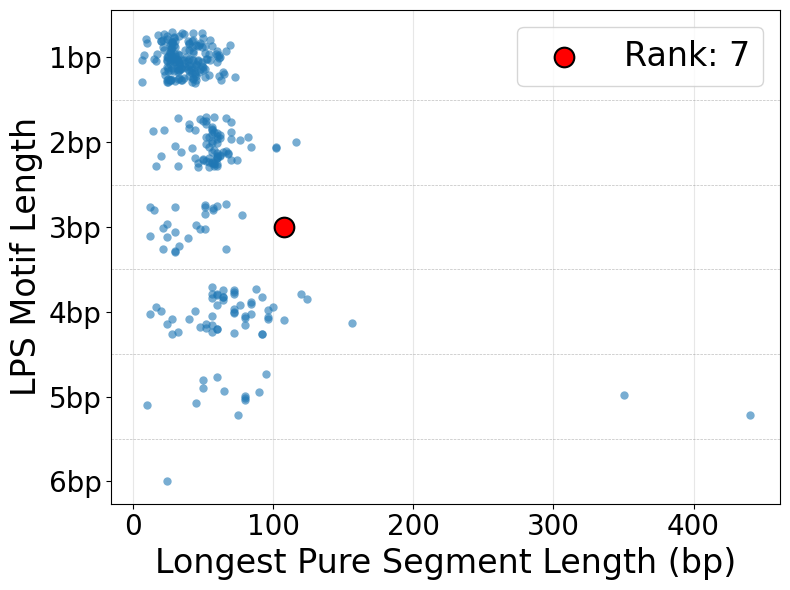

In [8]:
# re-draw plot using a red circle
import pandas as pd
ranked=pd.read_csv('assets/outlierAnalyses/ATXN2/ATXN2_case_trgt.TR-Explorer_1.0.1_DiscoveryCohort_prioritized_ranks.txt',sep='\t')
pathogenicTRID="12-111598949-111599018-GCT"

# Create the swimlane plot
import matplotlib as mpl
import seaborn as sns
plt.figure(figsize=(8, 6))

# Define motif categories
motif_categories = ['1bp', '2bp', '3bp', '4bp', '5bp', '6bp']
ranked=ranked.loc[ranked['Motif_Length_Category'].isin(motif_categories),:].reset_index(drop=True)

# get rank of pathogenic variant
overall_rank=ranked[ranked['TRID'] == pathogenicTRID].index.values[0]+1

# Create stripplot with categories
pathogenic_data = ranked[ranked['TRID'] == pathogenicTRID]
# drop the pathogenic entry from sample4_sorted
ranked2 = ranked[ranked['TRID'] != pathogenicTRID]
sns.stripplot(data=ranked2,
            y='Motif_Length_Category',
            x='LPS_Length',
            order=motif_categories,
            alpha=0.6,
            size=6,
            jitter=0.3)

# Add thin dashed grey lines between strips
for i in range(len(motif_categories) - 1):
    plt.axhline(y=i + 0.5, color='grey', linestyle='--', linewidth=0.5, alpha=0.5)

# Highlight the pathogenic TRID if found
plt.scatter(pathogenic_data['LPS_Length'],
            pathogenic_data['Motif_Length_Category'],
            color='red',
            s=200,
            marker='o',
            zorder=5,
            label=f'Rank: {overall_rank}',
            edgecolors='black',
            linewidths=1.5)

plt.xlabel('Longest Pure Segment Length (bp)', fontsize=24)
plt.ylabel('LPS Motif Length', fontsize=24)
plt.tick_params(labelsize=20)
plt.legend(loc='upper right',fontsize=24)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()

# Save the plot
plt.savefig("figures/SupplementaryFigure10C.png", dpi=600, bbox_inches='tight')
plt.savefig("figures/SupplementaryFigure10C.svg", bbox_inches='tight')

## S10D

In [ ]:
%%bash
# ATXN3 Case using HiFi data
SAMPLEID="ATXN3_case"
repeat_catalog_nickname="TR-Explorer_v1.0.1"
repeat_catalog_nickname2="TR-Explorer_v1.0.1_AoUPhase1"
catalog_lps_stats="DiscoveryCohort_lpsPerMotifStats_trgt.TR_Explorer_1.0.1.txt.gz"
pathogenicTRID="14-92071010-92071040-CTG"
bcftools query -f "${SAMPLEID}\t%INFO/TRID\t%INFO/MOTIFS\t[%TGT\t%AL{0}\t%AL{1}\t%SD{0}\t%SD{1}\t%AM{0}\t%AM{1}]" ${SAMPLEID}_${repeat_catalog_nickname}_trgt.vcf.gz > ${SAMPLEID}_${repeat_catalog_nickname}_trgt.txt
python scripts/prioritizeTRWithinSample.py --inputFile=${SAMPLEID}_${repeat_catalog_nickname}_trgt.txt --sampleID=${SAMPLEID} --comparisonCatalog=${catalog_lps_stats} --comparisonCatalogNickname=${repeat_catalog_nickname2} --pathogenicTRID=${pathogenicTRID}


c:\Users\Matt\anaconda3\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Matt\anaconda3\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Matt\anaconda3\lib\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


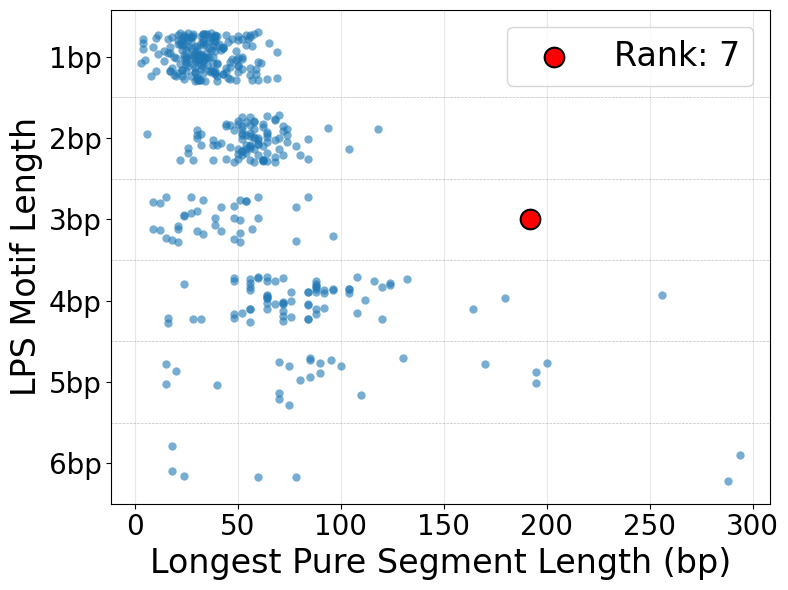

In [9]:
# re-draw plot using a red circle
import pandas as pd
ranked=pd.read_csv('assets/outlierAnalyses/ATXN3/ATXN3_case_trgt.TR-Explorer_1.0.1_DiscoveryCohort_prioritized_ranks.txt',sep='\t')
pathogenicTRID="14-92071010-92071040-CTG"

# Create the swimlane plot
import matplotlib as mpl
import seaborn as sns
plt.figure(figsize=(8, 6))

# Define motif categories
motif_categories = ['1bp', '2bp', '3bp', '4bp', '5bp', '6bp']
ranked=ranked.loc[ranked['Motif_Length_Category'].isin(motif_categories),:].reset_index(drop=True)

# get rank of pathogenic variant
overall_rank=ranked[ranked['TRID'] == pathogenicTRID].index.values[0]+1

# Create stripplot with categories
pathogenic_data = ranked[ranked['TRID'] == pathogenicTRID]
# drop the pathogenic entry from sample4_sorted
ranked2 = ranked[ranked['TRID'] != pathogenicTRID]
sns.stripplot(data=ranked2,
            y='Motif_Length_Category',
            x='LPS_Length',
            order=motif_categories,
            alpha=0.6,
            size=6,
            jitter=0.3)

# Add thin dashed grey lines between strips
for i in range(len(motif_categories) - 1):
    plt.axhline(y=i + 0.5, color='grey', linestyle='--', linewidth=0.5, alpha=0.5)

# Highlight the pathogenic TRID if found
plt.scatter(pathogenic_data['LPS_Length'],
            pathogenic_data['Motif_Length_Category'],
            color='red',
            s=200,
            marker='o',
            zorder=5,
            label=f'Rank: {overall_rank}',
            edgecolors='black',
            linewidths=1.5)

plt.xlabel('Longest Pure Segment Length (bp)', fontsize=24)
plt.ylabel('LPS Motif Length', fontsize=24)
plt.tick_params(labelsize=20)
plt.legend(loc='upper right',fontsize=24)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()

# Save the plot
plt.savefig("figures/SupplementaryFigure10D.png", dpi=600, bbox_inches='tight')
plt.savefig("figures/SupplementaryFigure10D.svg", bbox_inches='tight')

## S10E

In [ ]:
%%bash
# ATN1 Case using HiFi data
SAMPLEID="ATN1_case"
repeat_catalog_nickname="TR-Explorer_v1.0.1"
repeat_catalog_nickname2="TR-Explorer_v1.0.1_AoUPhase1"
catalog_lps_stats="DiscoveryCohort_lpsPerMotifStats_trgt.TR_Explorer_1.0.1.txt.gz"
pathogenicTRID="12-6936716-6936773-CAG"
bcftools query -f "${SAMPLEID}\t%INFO/TRID\t%INFO/MOTIFS\t[%TGT\t%AL{0}\t%AL{1}\t%SD{0}\t%SD{1}\t%AM{0}\t%AM{1}]" ${SAMPLEID}_${repeat_catalog_nickname}_trgt.vcf.gz > ${SAMPLEID}_${repeat_catalog_nickname}_trgt.txt
python scripts/prioritizeTRWithinSample.py --inputFile=${SAMPLEID}_${repeat_catalog_nickname}_trgt.txt --sampleID=${SAMPLEID} --comparisonCatalog=${catalog_lps_stats} --comparisonCatalogNickname=${repeat_catalog_nickname2} --pathogenicTRID=${pathogenicTRID}


c:\Users\Matt\anaconda3\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Matt\anaconda3\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Matt\anaconda3\lib\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


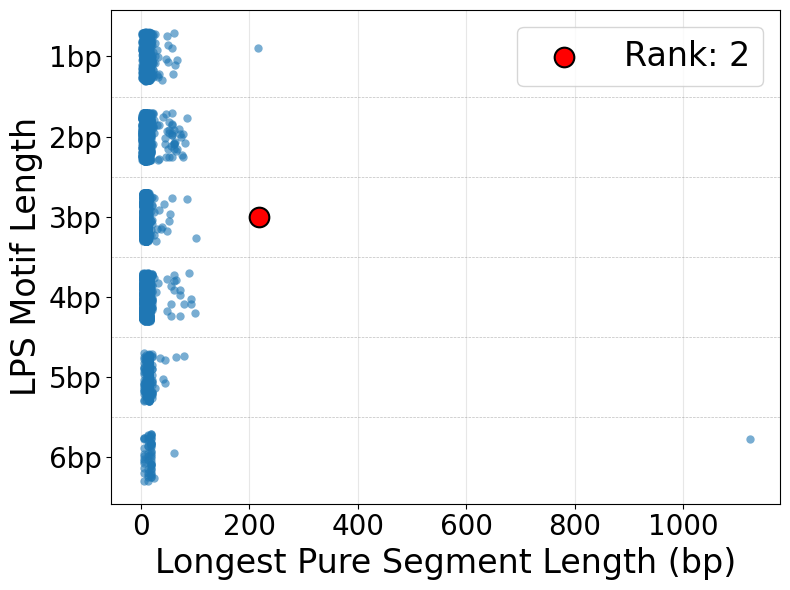

In [10]:
# re-draw plot using a red circle
import pandas as pd
ranked=pd.read_csv('assets/outlierAnalyses/ATN1/ATN1_case_trgt.TR-Explorer_v1.0.1_AoUPhase1_prioritized_ranks.txt',sep='\t')
pathogenicTRID="12-6936716-6936773-CAG"

# Create the swimlane plot
import matplotlib as mpl
import seaborn as sns
plt.figure(figsize=(8, 6))

# Define motif categories
motif_categories = ['1bp', '2bp', '3bp', '4bp', '5bp', '6bp']
ranked=ranked.loc[ranked['Motif_Length_Category'].isin(motif_categories),:].reset_index(drop=True)

# get rank of pathogenic variant
overall_rank=ranked[ranked['TRID'] == pathogenicTRID].index.values[0]+1

# Create stripplot with categories
pathogenic_data = ranked[ranked['TRID'] == pathogenicTRID]
# drop the pathogenic entry from sample4_sorted
ranked2 = ranked[ranked['TRID'] != pathogenicTRID]
sns.stripplot(data=ranked2,
            y='Motif_Length_Category',
            x='LPS_Length',
            order=motif_categories,
            alpha=0.6,
            size=6,
            jitter=0.3)

# Add thin dashed grey lines between strips
for i in range(len(motif_categories) - 1):
    plt.axhline(y=i + 0.5, color='grey', linestyle='--', linewidth=0.5, alpha=0.5)

# Highlight the pathogenic TRID if found
plt.scatter(pathogenic_data['LPS_Length'],
            pathogenic_data['Motif_Length_Category'],
            color='red',
            s=200,
            marker='o',
            zorder=5,
            label=f'Rank: {overall_rank}',
            edgecolors='black',
            linewidths=1.5)

plt.xlabel('Longest Pure Segment Length (bp)', fontsize=24)
plt.ylabel('LPS Motif Length', fontsize=24)
plt.tick_params(labelsize=20)
plt.legend(loc='upper right',fontsize=24)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()

# Save the plot
plt.savefig("figures/SupplementaryFigure10E.png", dpi=600, bbox_inches='tight')
plt.savefig("figures/SupplementaryFigure10E.svg", bbox_inches='tight')

# S11: Variation at Disease-associated STRs

In [25]:
# boxplot of the distributions of allele lengths for each disease-associated STR, ordered by median size
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sb
import matplotlib
from matplotlib.colors import to_rgba

mpl.rcParams['svg.fonttype'] = 'none'  # keep SVG text in SVGs

alleleLengths=pd.read_csv('assets/pathogenicSTRs_alleleInfo_noIDs.txt',sep='\t',header=None,
                          names=['TRID','Allele1','Allele2','Allele1_LPS_Length','Allele1_LPS_Motif','Allele2_LPS_Length','Allele2_LPS_Motif','Allele1_Len','Allele2_Len'])

# Define pathogenic and poly-alanine TRIDs
pathogenic=pd.read_csv('assets/pathogenicTRIDs_TRExplorer_v1.0.1_STRchiveFiltered_noVNTRs_withAnno.txt',sep='\t')
alleleLengths=alleleLengths.merge(pathogenic,how='inner',on='TRID')
alleleLengths


,TRID,Allele1,Allele2,Allele1_LPS_Length,Allele1_LPS_Motif,Allele2_LPS_Length,Allele2_LPS_Motif,Allele1_Len,Allele2_Len,geneName,Region
0,1-57367043-57367118-AAAAT,CAAAATAAAATAAAATAAAATAAAATAAAATAAAAT,CAAAATAAAATAAAATAAAATAAAATAAAATAAAATAAAATAAAAT...,35,AAAAT,70,AAAAT,35,70,DAB1,intron
1,1-94418421-94418442-GCC,AGCCGCCGCCGCCGCCGCCGCC,AGCCGCCGCCGCCGCCGCCGCC,21,GCC,21,GCC,21,21,ABCD3,UTR_5
2,1-149390802-149390841-GGC,AGGCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGC...,AGGCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGC...,45,GGC,63,GGC,57,75,NOTCH2NLC,UTR_5
3,1-57367043-57367118-AAAAT,CAAAATAAAATAAAATAAAATAAAATAAAATAAAATAAAATAAAAT...,CAAAATAAAATAAAATAAAATAAAATAAAATAAAATAAAATAAAAT...,70,AAAAT,90,AAAAT,70,90,DAB1,intron
4,1-94418421-94418442-GCC,AGCCGCCGCCGCCGCCGCCGCC,AGCCGCCGCCGCCGCCGCCGCC,21,GCC,21,GCC,21,21,ABCD3,UTR_5
...,...,...,...,...,...,...,...,...,...,...,...
28774,X-25013649-25013697-NGC,TGGCGGCCGCTGCCGCCGCCGCCGCCGCCGCCGCCGCCGCCGCTGCCGC,.,30,CCG,-1,NaN,48,.,ARX,coding
28775,"X-67545306-67545318-TGC,X-67545400-67545419-GCA",TTGCTGCTGCTGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGC...,.,57,GCA,-1,NaN,101,.,AR,coding
28776,X-140504316-140504361-NGC,TGGCGGCAGCGGCTGCGGCCGCGGCAGCGGCGGCGGCGGCCGCGGC,.,12,CGG,-1,NaN,45,.,SOX3,coding
28777,X-147912050-147912110-CGG,GCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGGCGG...,.,57,CGG,-1,NaN,87,.,FMR1,UTR_5


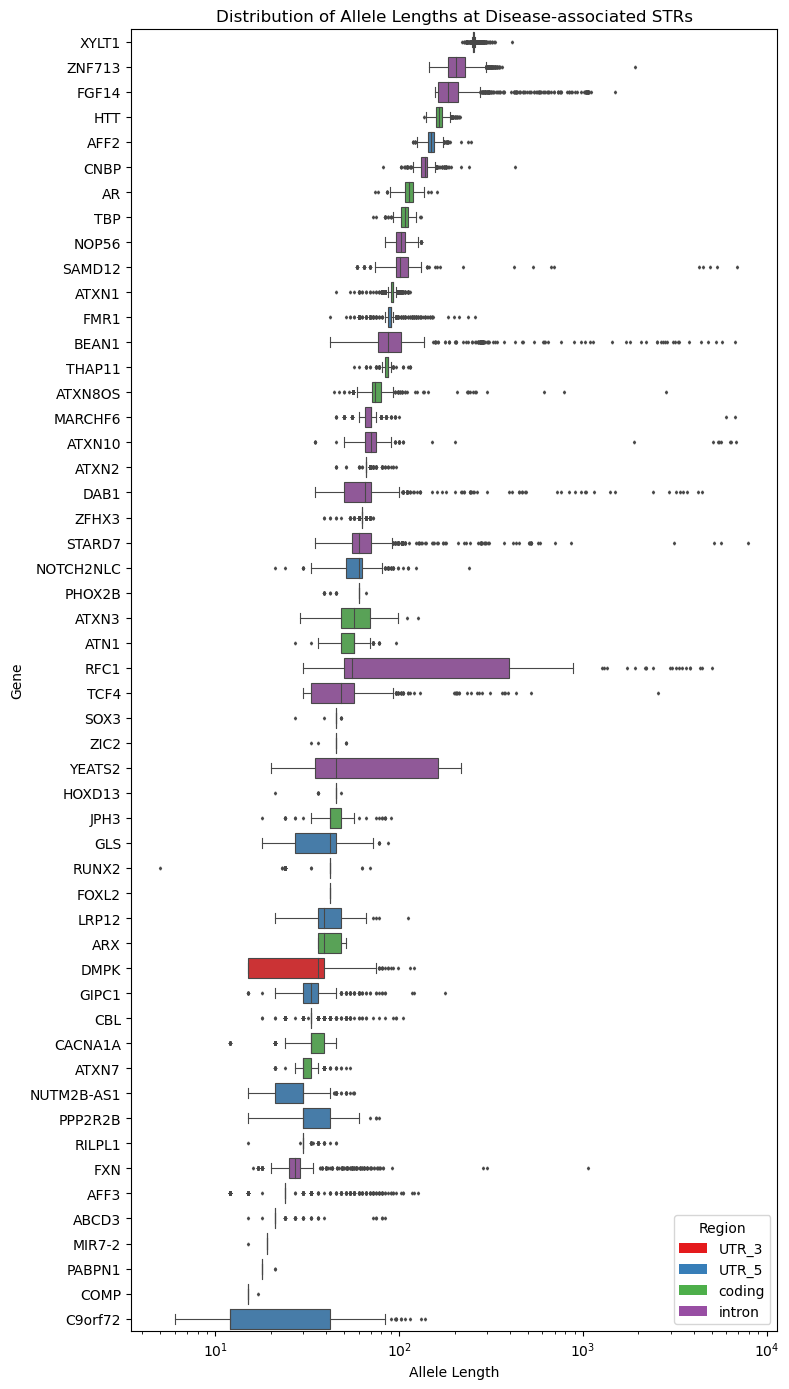

In [32]:
# Melt allele lengths to long format and plot per-gene boxplots colored by Region
al = alleleLengths.copy()
al['Allele1_Len'] = pd.to_numeric(al['Allele1_Len'], errors='coerce')
al['Allele2_Len'] = pd.to_numeric(al['Allele2_Len'], errors='coerce')

melted = al.melt(
    id_vars=['geneName', 'Region'],
    value_vars=['Allele1_Len', 'Allele2_Len'],
    var_name='AlleleNum',
    value_name='AlleleLength'
).dropna(subset=['AlleleLength'])

# Sort genes by median allele length (lowest at top, highest at bottom)
gene_order = (melted.groupby('geneName')['AlleleLength']
              .median()
              .sort_values(ascending=False)
              .index.tolist())

# Map each gene to its Region and assign colors
gene_region = melted.groupby('geneName')['Region'].first()
region_colors = {'UTR_3': '#e41a1c', 'UTR_5': '#377eb8', 'coding': '#4daf4a', 'intron': '#984ea3'}
palette = {gene: region_colors.get(gene_region[gene], 'gray') for gene in gene_order}

fig, ax = plt.subplots(figsize=(8, 14))
sb.boxplot(data=melted, y='geneName', x='AlleleLength', order=gene_order,
           palette=palette, fliersize=1.5, linewidth=0.8, ax=ax)

ax.set_xlabel('Allele Length')
ax.set_ylabel('Gene')
ax.set_title('Distribution of Allele Lengths at Disease-associated STRs')
plt.xscale('log')

from matplotlib.patches import Patch
present_regions = [r for r in ['UTR_3', 'UTR_5', 'coding', 'intron'] if r in gene_region.values]
legend_handles = [Patch(facecolor=region_colors[r], label=r) for r in present_regions]
ax.legend(handles=legend_handles, title='Region', loc='lower right')

plt.tight_layout()
plt.savefig('figures/SupplementaryFigure11.png',dpi=600)
plt.savefig('figures/SupplementaryFigure11.svg')



# S12: FMR1 Interruptions

## S12A

In [50]:
import pandas
fmr1Alleles=pandas.read_csv('assets/FMR1_alleleInfo_noIDs.txt',sep='\t',header=None,names=
                            ['TRID','Allele1','Allele2','Allele1_LPS_Length','Allele1_LPS_Motif','Allele2_LPS_Length','Allele2_LPS_Motif','Allele1_Len','Allele2_Len'])
fmr1Alleles

,TRID,Allele1,Allele2,Allele1_LPS_Length,Allele1_LPS_Motif,Allele2_LPS_Length,Allele2_LPS_Motif,Allele1_Len,Allele2_Len
0,X-147912050-147912110-CGG,GCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGGCGG...,GCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGG...,27,CGG,30,CGG,87,90
1,X-147912050-147912110-CGG,GCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGG...,GCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGG...,30,CGG,30,CGG,90,90
2,X-147912050-147912110-CGG,GCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGG...,GCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGG...,30,CGG,60,CGG,90,99
3,X-147912050-147912110-CGG,GCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGGCGG...,GCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGG...,27,CGG,30,CGG,87,90
4,X-147912050-147912110-CGG,GCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGG...,GCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGG...,30,CGG,30,CGG,90,90
...,...,...,...,...,...,...,...,...,...
538,X-147912050-147912110-CGG,GCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGGCGG...,GCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGG...,27,CGG,30,CGG,87,90
539,X-147912050-147912110-CGG,GCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGG...,GCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGG...,30,CGG,120,CGG,93,153
540,X-147912050-147912110-CGG,GCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGGCGG...,GCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGG...,30,CGG,30,CGG,90,93
541,X-147912050-147912110-CGG,GCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGG...,GCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGG...,30,CGG,30,CGG,90,123


In [51]:
import re
allele1 = fmr1Alleles[['TRID', 'Allele1']].copy().rename(columns={'Allele1':'Allele'})
allele2 = fmr1Alleles[['TRID', 'Allele2']].copy().rename(columns={'Allele2':'Allele'})
alleles=pandas.concat([allele1,allele2], ignore_index=True)
alleles=alleles.loc[alleles['Allele']!=".",:]
alleles['Allele_CGG'] = alleles['Allele'].apply(lambda seq: len(re.findall('CGG', seq)))
alleles['Allele_AGG'] = alleles['Allele'].apply(lambda seq: len(re.findall('AGG', seq)))
alleles['totalTriplets']=alleles.loc[:,'Allele_CGG'] + alleles.loc[:,'Allele_AGG']
alleles

,TRID,Allele,Allele_CGG,Allele_AGG,totalTriplets
0,X-147912050-147912110-CGG,GCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGGCGG...,27,2,29
1,X-147912050-147912110-CGG,GCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGG...,28,2,30
2,X-147912050-147912110-CGG,GCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGG...,28,2,30
3,X-147912050-147912110-CGG,GCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGGCGG...,27,2,29
4,X-147912050-147912110-CGG,GCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGG...,28,2,30
...,...,...,...,...,...
1079,X-147912050-147912110-CGG,GCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGG...,28,2,30
1081,X-147912050-147912110-CGG,GCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGG...,28,2,30
1082,X-147912050-147912110-CGG,GCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGG...,50,1,51
1083,X-147912050-147912110-CGG,GCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGG...,29,2,31


In [62]:
print(f'Alleles with under 24 triplets: {len(alleles.loc[alleles["totalTriplets"]<24,:])}')
print(f'Alleles with 24-34 triplets: {len(alleles.loc[((alleles["totalTriplets"]>=24) & (alleles["totalTriplets"]<35)),:])}')
print(f'Alleles with 35-44 triplets: {len(alleles.loc[((alleles["totalTriplets"]>=35) & (alleles["totalTriplets"]<45)),:])}')
print(f'Alleles with 45-54 triplets: {len(alleles.loc[((alleles["totalTriplets"]>=45) & (alleles["totalTriplets"]<54)),:])}')
print(f'Alleles with over 54 triplets: {len(alleles.loc[alleles["totalTriplets"]>54,:])}')
print(f'Alleles with 29 triplets: {len(alleles.loc[alleles["totalTriplets"]==29,:])}')
print(f'Alleles with 30 triplets: {len(alleles.loc[alleles["totalTriplets"]==30,:])}')
print(f'Alleles with 31 triplets: {len(alleles.loc[alleles["totalTriplets"]==31,:])}')


Alleles with under 24 triplets: 79
Alleles with 24-34 triplets: 750
Alleles with 35-44 triplets: 48
Alleles with 45-54 triplets: 14
Alleles with over 54 triplets: 5
Alleles with 29 triplets: 244
Alleles with 30 triplets: 363
Alleles with 31 triplets: 77


In [54]:
alleles.loc[:,'Allele_AGG'].min()

0

In [55]:
alleles.loc[:,'Allele_AGG'].max()

5

In [57]:
print(f'Percentage of alleles with 0 interruptions: {100*len(alleles.loc[alleles["Allele_AGG"]==0,:])/len(alleles)}')
print(f'Percentage of alleles with 1 interruptions: {100*len(alleles.loc[alleles["Allele_AGG"]==1,:])/len(alleles)}')
print(f'Percentage of alleles with 2 interruptions: {100*len(alleles.loc[alleles["Allele_AGG"]==2,:])/len(alleles)}')
print(f'Percentage of alleles with 3 interruptions: {100*len(alleles.loc[alleles["Allele_AGG"]==3,:])/len(alleles)}')
print(f'Percentage of alleles with 4 interruptions: {100*len(alleles.loc[alleles["Allele_AGG"]==4,:])/len(alleles)}')
print(f'Percentage of alleles with 5 interruptions: {100*len(alleles.loc[alleles["Allele_AGG"]==5,:])/len(alleles)}')



Percentage of alleles with 0 interruptions: 3.236607142857143
Percentage of alleles with 1 interruptions: 19.308035714285715
Percentage of alleles with 2 interruptions: 75.22321428571429
Percentage of alleles with 3 interruptions: 1.7857142857142858
Percentage of alleles with 4 interruptions: 0.33482142857142855
Percentage of alleles with 5 interruptions: 0.11160714285714286


In [ ]:
print(f'Percentage of high normal alleles with 3+ interruptions: {100*len(alleles.loc[((alleles["totalTriplets"]>=35) & (alleles["totalTriplets"]<45) & (alleles["Allele_AGG"]>=3)),:])/len(alleles.loc[((alleles["totalTriplets"]>=35) & (alleles["totalTriplets"]<45)),:])}')
print(f'Percentage of grey zone alleles with 3+ interruptions: {100*len(alleles.loc[((alleles["totalTriplets"]>=45) & (alleles["totalTriplets"]<54) & (alleles["Allele_AGG"]>=3)),:])/len(alleles.loc[((alleles["totalTriplets"]>=45) & (alleles["totalTriplets"]<54)),:])}')
print(f'Percentage of grey zone alleles with 4+ interruptions: {100*len(alleles.loc[((alleles["totalTriplets"]>=45) & (alleles["totalTriplets"]<54) & (alleles["Allele_AGG"]>=4)),:])/len(alleles.loc[((alleles["totalTriplets"]>=45) & (alleles["totalTriplets"]<54)),:])}')


Percentage of high normal alleles with 3+ interruptions: 31.25
Percentage of grey zone alleles with 3+ interruptions: 21.428571428571427
Percentage of grey zone alleles with 4+ interruptions: 21.428571428571427


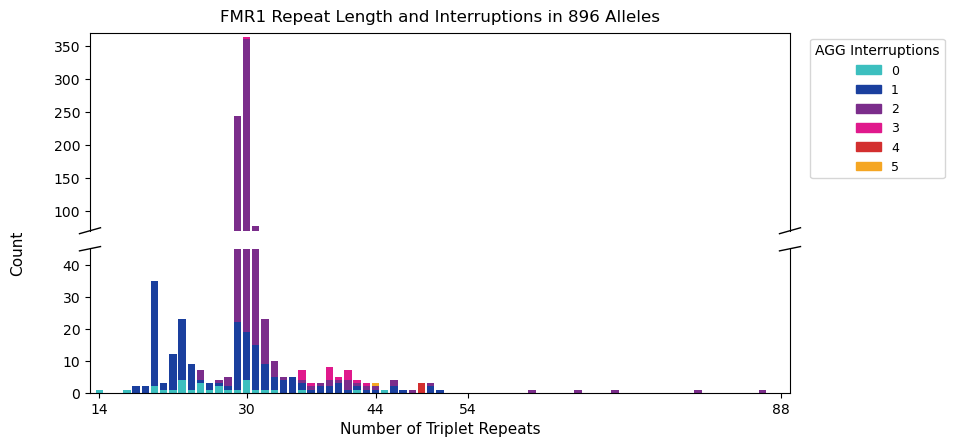

In [48]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# Color palette for AGG interruption counts 0-5
agg_colors = {0: '#3cbfbf', 1: '#1a3f9e', 2: '#7b2d8b', 3: '#e0198c', 4: '#d32f2f', 5: '#f5a623'}
n_alleles = len(alleles)

# --- Pivot data for Panel A ---
pivot_a = alleles.groupby(['totalTriplets', 'Allele_AGG']).size().unstack(fill_value=0)
x_vals = pivot_a.index.values
agg_vals = sorted(pivot_a.columns.tolist())

# --- Pivot data for Panel B ---
bins = [13, 23, 34, 44, 54, 88]
bin_labels = ['(13, 23]', '(23, 34]', '(34, 44]', '(44, 54]', '(54, 88]']
alleles2 = alleles.copy()
alleles2['RepeatBin'] = pandas.cut(alleles2['totalTriplets'], bins=bins, labels=bin_labels)
pivot_b = alleles2.groupby(['RepeatBin', 'Allele_AGG'], observed=True).size().unstack(fill_value=0)
pivot_b_norm = pivot_b.div(pivot_b.sum(axis=1), axis=0)
bin_counts = alleles2.groupby('RepeatBin', observed=True).size()

# ===== Build figure =====
fig = plt.figure(figsize=(10, 9))

# ---- Panel A: Broken y-axis stacked histogram ----
# Top portion (high counts)
ax_top = fig.add_axes([0.12, 0.60, 0.70, 0.22])
# Bottom portion (low counts)
ax_bot = fig.add_axes([0.12, 0.42, 0.70, 0.16], sharex=ax_top)

for ax in [ax_top, ax_bot]:
    bottom = np.zeros(len(x_vals))
    for agg in agg_vals:
        if agg in pivot_a.columns:
            vals = pivot_a[agg].values
            ax.bar(x_vals, vals, bottom=bottom,
                   color=agg_colors.get(agg, 'grey'), label=str(agg), width=0.8)
            bottom += vals

ax_top.set_ylim(70, 370)
ax_bot.set_ylim(0, 45)

# Hide inner spines for broken-axis effect
ax_top.spines['bottom'].set_visible(False)
ax_bot.spines['top'].set_visible(False)
ax_top.tick_params(labelbottom=False, bottom=False)

# Draw diagonal break markers
d = 0.015
kw = dict(color='k', clip_on=False, linewidth=1)
ax_top.plot([-d, +d], [-d, +d], transform=ax_top.transAxes, **kw)
ax_top.plot([1-d, 1+d], [-d, +d], transform=ax_top.transAxes, **kw)
ax_bot.plot([-d, +d], [1-d, 1+d], transform=ax_bot.transAxes, **kw)
ax_bot.plot([1-d, 1+d], [1-d, 1+d], transform=ax_bot.transAxes, **kw)

ax_bot.set_xlim(13, 89)
ax_bot.set_xticks([14, 30, 44, 54, 88])
ax_bot.set_xlabel('Number of Triplet Repeats', fontsize=11)
fig.text(0.04, 0.575, 'Count', va='center', rotation='vertical', fontsize=11)
ax_top.set_title(f'FMR1 Repeat Length and Interruptions in {n_alleles} Alleles', fontsize=12, pad=8)

handles_a = [mpatches.Patch(color=agg_colors.get(a, 'grey'), label=str(a)) for a in agg_vals]
ax_top.legend(handles=handles_a, title='AGG Interruptions',
              bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9)
plt.savefig('figures/SupplementaryFigure12A.png',dpi=600)
plt.savefig('figures/SupplementaryFigure12A.svg')


## S12B

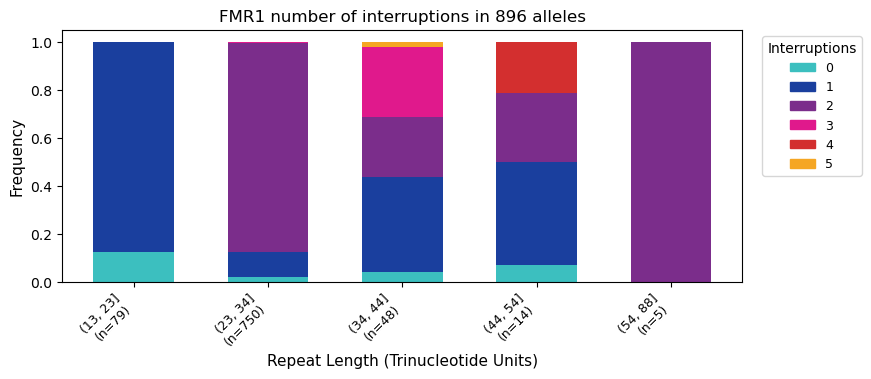

In [49]:
fig = plt.figure(figsize=(10, 9))
# ---- Panel B: Normalized stacked bars by repeat-length bin ----
ax_b = fig.add_axes([0.12, 0.07, 0.68, 0.28])
x_pos = np.arange(len(bin_labels))
bottom_b = np.zeros(len(bin_labels))
agg_vals_b = sorted(pivot_b_norm.columns.tolist())

for agg in agg_vals_b:
    if agg in pivot_b_norm.columns:
        vals = pivot_b_norm[agg].reindex(bin_labels, fill_value=0).values
        ax_b.bar(x_pos, vals, bottom=bottom_b,
                 color=agg_colors.get(agg, 'grey'), label=str(agg), width=0.6)
        bottom_b += vals

x_tick_labels = [f'{lbl}\n(n={bin_counts.get(lbl, 0)})' for lbl in bin_labels]
ax_b.set_xticks(x_pos)
ax_b.set_xticklabels(x_tick_labels, rotation=45, ha='right', fontsize=9)
ax_b.set_ylabel('Frequency', fontsize=11)
ax_b.set_xlabel('Repeat Length (Trinucleotide Units)', fontsize=11)
ax_b.set_title(f'FMR1 number of interruptions in {n_alleles} alleles', fontsize=12)
ax_b.set_ylim(0, 1.05)

handles_b = [mpatches.Patch(color=agg_colors.get(a, 'grey'), label=str(a)) for a in agg_vals_b]
ax_b.legend(handles=handles_b, title='Interruptions',
            bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9)

plt.savefig('figures/SupplementaryFigure12B.png', dpi=600)
plt.savefig('figures/SupplementaryFigure12B.svg')


# S13: Disease-associated STR Enrichment in srWGS

## S13A

In [15]:
# caluclate the proportion of the pathogenic TRs that rank above the 90th, 95th, and 99th percentiles
# initial data loading and package import
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sb
import matplotlib
from matplotlib.colors import to_rgba

mpl.rcParams['svg.fonttype'] = 'none'  # keep SVG text in SVGs

totalLenAoU=pd.read_csv('statsTables/aou704_srWGS_alleleLengthStats.txt.gz',sep='\t')

# get reference motif lengths
catalog=pd.read_csv('assets/srWGS_IDs_with_motifs.txt',sep='\t',header=None,names=['TRID','refMotif'])
catalog['refMotifLen']=catalog.loc[:,'refMotif'].str.len()

# calculate percentile of standard deviation normalized by ref motif len
totalLenAoU=totalLenAoU.merge(catalog,how='inner',on='TRID')
totalLenAoU['percentile_stdev']=totalLenAoU.groupby('refMotifLen',observed=True)['std'].rank(pct=True)

# Define pathogenic and poly-alanine TRIDs
pathogenic=pd.read_csv('assets/pathogenicTRIDs_AoUsrWGS704_withAnno.txt',sep='\t')

polyAlanineTRNames = ['ARX','NIPA1','HOXA13','PHOX2B','SOX3','HOXD13','ZIC2','RUNX2','PABPN1','FOXL2']
polyAlanineTRIDs = pathogenic.loc[pathogenic['geneName'].isin(polyAlanineTRNames),'TRID'].values
singleShiftTRNames = ['MIR7-2','COMP']
singleShiftTRIDs = pathogenic.loc[pathogenic['geneName'].isin(singleShiftTRNames),'TRID'].values
otherPathogenicTRIDs = pathogenic.loc[((~pathogenic['geneName'].isin(polyAlanineTRNames)) & (~pathogenic['geneName'].isin(singleShiftTRNames))),'TRID'].values


# mark pathogenic TRs
totalLenAoU['patho']=0
totalLenAoU.loc[totalLenAoU['TRID'].isin(otherPathogenicTRIDs),'patho']=1

# calculate odds ratios
from statsmodels.stats.contingency_tables import Table2x2
def calculate_enrichment_with_ci(df, percentile_threshold, pathogenic_col='patho'):
    above_threshold = df['percentile_stdev'] > percentile_threshold
    
    a = ((df[pathogenic_col] == 1) & above_threshold).sum()
    b = ((df[pathogenic_col] == 0) & above_threshold).sum()
    c = ((df[pathogenic_col] == 1) & ~above_threshold).sum()
    d = ((df[pathogenic_col] == 0) & ~above_threshold).sum()
    
    table = Table2x2([[a, b], [c, d]])
    
    return {
        'odds_ratio': table.oddsratio,
        'p_value': table.oddsratio_pvalue(),
        'ci_95': table.oddsratio_confint(alpha=0.05),
        'contingency_table': [[a, b], [c, d]],
        'n_pathogenic_above': a,
        'n_pathogenic_total': a + c,
        'n_total_above': a + b
    }


print("\n=== Non-polyAlanine and non-single-shift Pathogenic TRs ===")
for threshold in [0.80, 0.90, 0.95, 0.99]:
    stats = calculate_enrichment_with_ci(totalLenAoU, threshold)
    print(f"\nAbove {threshold*100:.0f}th percentile:")
    print(f"  Contingency table: {stats['contingency_table']}")
    print(f"  Odds Ratio: {stats['odds_ratio']:.2f}")
    print(f"  Confidence Interval: {stats['ci_95']}")
    print(f"  P-value: {stats['p_value']:.2e}")
    print(f"  Pathogenic above threshold: {stats['n_pathogenic_above']}/{stats['n_pathogenic_total']} ({stats['n_pathogenic_above']/stats['n_pathogenic_total']:.1%})")






=== Non-polyAlanine and non-single-shift Pathogenic TRs ===

Above 80th percentile:
  Contingency table: [[22, 34845], [3, 139430]]
  Odds Ratio: 29.34
  Confidence Interval: (8.782416808152304, 98.04384272337526)
  P-value: 4.02e-08
  Pathogenic above threshold: 22/25 (88.0%)

Above 90th percentile:
  Contingency table: [[19, 17422], [6, 156853]]
  Odds Ratio: 28.51
  Confidence Interval: (11.384856756211114, 71.39483112102579)
  P-value: 8.48e-13
  Pathogenic above threshold: 19/25 (76.0%)

Above 95th percentile:
  Contingency table: [[18, 8709], [7, 165566]]
  Odds Ratio: 48.89
  Confidence Interval: (20.41298725133118, 117.07066838237722)
  P-value: 2.57e-18
  Pathogenic above threshold: 18/25 (72.0%)

Above 99th percentile:
  Contingency table: [[11, 1750], [14, 172525]]
  Odds Ratio: 77.46
  Confidence Interval: (35.11644730742675, 170.86247830939374)
  P-value: 4.44e-27
  Pathogenic above threshold: 11/25 (44.0%)


In [16]:
import scipy.stats
# calculate generalized odds ratio for this statistic
group1=totalLenAoU.loc[totalLenAoU['patho']==1,'percentile_stdev'].dropna().values
group2=totalLenAoU.loc[:,'percentile_stdev'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")



Raw U Statistic: 4072841.5
P-Value: 2.5720312629710714e-14
Probability of Superiority: 0.9347
Generalized Odds Ratio: 14.3078


In [17]:
# caluclate the proportion of the pathogenic TRs that rank above the 90th, 95th, and 99th percentiles
# initial data loading and package import
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sb
import matplotlib
from matplotlib.colors import to_rgba

mpl.rcParams['svg.fonttype'] = 'none'  # keep SVG text in SVGs

totalLen=pd.read_csv('statsTables/ensembleTR_alleleLengthStats.txt.gz',sep='\t')

# get reference motif lengths
catalog=pd.read_csv('assets/ensembleTR_IDs_with_motif_length.txt',sep='\t',header=None,names=['TRID','refMotifLen'])

# calculate percentile of standard deviation normalized by ref motif len
totalLen=totalLen.merge(catalog,how='inner',on='TRID')
totalLen['percentile_stdev']=totalLen.groupby('refMotifLen',observed=True)['std'].rank(pct=True)

# Define pathogenic and poly-alanine TRIDs
pathogenic=pd.read_csv('assets/pathogenicTRIDs_ensembleTR_withAnno.txt',sep='\t')

polyAlanineTRNames = ['ARX','NIPA1','HOXA13','PHOX2B','SOX3','HOXD13','ZIC2','RUNX2','PABPN1','FOXL2']
polyAlanineTRIDs = pathogenic.loc[pathogenic['geneName'].isin(polyAlanineTRNames),'TRID'].values
singleShiftTRNames = ['MIR7-2','COMP']
singleShiftTRIDs = pathogenic.loc[pathogenic['geneName'].isin(singleShiftTRNames),'TRID'].values
otherPathogenicTRIDs = pathogenic.loc[((~pathogenic['geneName'].isin(polyAlanineTRNames)) & (~pathogenic['geneName'].isin(singleShiftTRNames))),'TRID'].values


# mark pathogenic TRs
totalLen['patho']=0
totalLen.loc[totalLen['TRID'].isin(otherPathogenicTRIDs),'patho']=1

# calculate odds ratios
from statsmodels.stats.contingency_tables import Table2x2
def calculate_enrichment_with_ci(df, percentile_threshold, pathogenic_col='patho'):
    above_threshold = df['percentile_stdev'] > percentile_threshold
    
    a = ((df[pathogenic_col] == 1) & above_threshold).sum()
    b = ((df[pathogenic_col] == 0) & above_threshold).sum()
    c = ((df[pathogenic_col] == 1) & ~above_threshold).sum()
    d = ((df[pathogenic_col] == 0) & ~above_threshold).sum()
    
    table = Table2x2([[a, b], [c, d]])
    
    return {
        'odds_ratio': table.oddsratio,
        'p_value': table.oddsratio_pvalue(),
        'ci_95': table.oddsratio_confint(alpha=0.05),
        'contingency_table': [[a, b], [c, d]],
        'n_pathogenic_above': a,
        'n_pathogenic_total': a + c,
        'n_total_above': a + b
    }


print("\n=== Non-polyAlanine and non-single-shift Pathogenic TRs ===")
for threshold in [0.80, 0.90, 0.95, 0.99]:
    stats = calculate_enrichment_with_ci(totalLen, threshold)
    print(f"\nAbove {threshold*100:.0f}th percentile:")
    print(f"  Contingency table: {stats['contingency_table']}")
    print(f"  Odds Ratio: {stats['odds_ratio']:.2f}")
    print(f"  Confidence Interval: {stats['ci_95']}")
    print(f"  P-value: {stats['p_value']:.2e}")
    print(f"  Pathogenic above threshold: {stats['n_pathogenic_above']}/{stats['n_pathogenic_total']} ({stats['n_pathogenic_above']/stats['n_pathogenic_total']:.1%})")




=== Non-polyAlanine and non-single-shift Pathogenic TRs ===

Above 80th percentile:
  Contingency table: [[30, 342823], [1, 1371261]]
  Odds Ratio: 120.00
  Confidence Interval: (16.36431979842959, 879.9234627464173)
  P-value: 2.48e-06
  Pathogenic above threshold: 30/31 (96.8%)

Above 90th percentile:
  Contingency table: [[30, 171414], [1, 1542670]]
  Odds Ratio: 269.99
  Confidence Interval: (36.819114704903726, 1979.8060933955542)
  P-value: 3.64e-08
  Pathogenic above threshold: 30/31 (96.8%)

Above 95th percentile:
  Contingency table: [[28, 85716], [3, 1628368]]
  Odds Ratio: 177.31
  Confidence Interval: (53.9038698884182, 583.2233914491068)
  P-value: 1.55e-17
  Pathogenic above threshold: 28/31 (90.3%)

Above 99th percentile:
  Contingency table: [[21, 17171], [10, 1696913]]
  Odds Ratio: 207.53
  Confidence Interval: (97.71833795030368, 440.7481468772041)
  P-value: 7.97e-44
  Pathogenic above threshold: 21/31 (67.7%)


In [18]:
import scipy.stats
# calculate generalized odds ratio for this statistic
group1=totalLen.loc[totalLen['patho']==1,'percentile_stdev'].dropna().values
group2=totalLen.loc[:,'percentile_stdev'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")



Raw U Statistic: 51468059.5
P-Value: 7.39062045926227e-20
Probability of Superiority: 0.9686
Generalized Odds Ratio: 30.8283


In [21]:
from statsmodels.stats.contingency_tables import Table2x2

def calculate_enrichment_with_ci(df, percentile_threshold, pathogenic_col='patho'):
    above_threshold = df['percentile_stdev'] > percentile_threshold
    
    a = ((df[pathogenic_col] == 1) & above_threshold).sum()
    b = ((df[pathogenic_col] == 0) & above_threshold).sum()
    c = ((df[pathogenic_col] == 1) & ~above_threshold).sum()
    d = ((df[pathogenic_col] == 0) & ~above_threshold).sum()
    
    table = Table2x2([[a, b], [c, d]])
    
    return {
        'odds_ratio': table.oddsratio,
        'p_value': table.oddsratio_pvalue(),
        'ci_95': table.oddsratio_confint(alpha=0.05),
        'contingency_table': [[a, b], [c, d]],
        'n_pathogenic_above': a,
        'n_pathogenic_total': a + c,
        'n_total_above': a + b
    }
# Collect n_pathogenic_above values for plotting
thresholds = [0.90, 0.95, 0.99, 0.999]
datasets = {
    'AoU srWGS Cohort': totalLenAoU,
    'EnsembleTR Cohort': totalLen
}
numPatho={'AoU srWGS Cohort':25,'EnsembleTR Cohort':31}

# Collect data for plotting
plot_data = []
for dataset_name, dataset in datasets.items():
    for threshold in thresholds:
        stats = calculate_enrichment_with_ci(dataset, threshold)
        plot_data.append({
            'Dataset': dataset_name,
            'Threshold': f'{threshold*100:.1f}th Percentile',
            'percent_pathogenic_above': 100*stats['n_pathogenic_above']/numPatho[dataset_name]
        })

# Convert to DataFrame for easier plotting
plot_df = pd.DataFrame(plot_data)

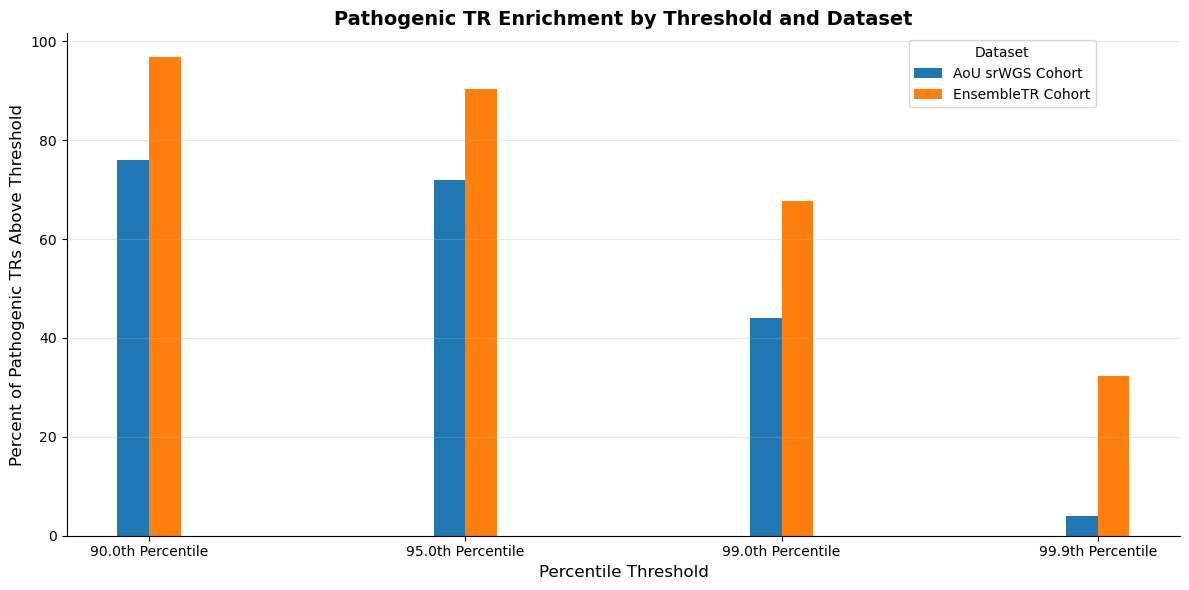

In [22]:
# Create grouped bar plot
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['svg.fonttype'] = 'none'
fig, ax = plt.subplots(figsize=(12, 6))

# Get unique thresholds and datasets
threshold_labels = [f'{t*100:.1f}th Percentile' for t in thresholds]
dataset_names = list(datasets.keys())

# Set up bar positions
x = np.arange(len(threshold_labels))
width = 0.1
offsets = np.arange(len(dataset_names)) * width - (len(dataset_names) - 1) * width / 2

# Plot bars for each dataset
for idx, dataset_name in enumerate(dataset_names):
    data_subset = plot_df[plot_df['Dataset'] == dataset_name]
    values = [data_subset[data_subset['Threshold'] == tl]['percent_pathogenic_above'].values[0] 
              for tl in threshold_labels]
    ax.bar(x + offsets[idx], values, width, label=dataset_name)

# Customize plot
ax.set_xlabel('Percentile Threshold', fontsize=12)
ax.set_ylabel('Percent of Pathogenic TRs Above Threshold', fontsize=12)
ax.set_title('Pathogenic TR Enrichment by Threshold and Dataset', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(threshold_labels)
ax.legend(title='Dataset', bbox_to_anchor=(0.75, 1), loc='upper left')
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('figures/SupplementaryFigure13.png',dpi=600)
plt.savefig('figures/SupplementaryFigure13.svg')

# S14: Network Analyses

In [ ]:
# I have no code for this figure

# Association Investigation

## 5'-UTR CGG repeats

In [149]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load data
lps=pd.read_csv('statsTables/DiscoveryCohort_lpsPerMotifStats.TR_Explorer_1.0.1.txt.gz',sep='\t')
annotations=pd.read_csv('assets/genicRegionAnnotations_TRExplorer.txt.gz',sep='\t',header=None,names=['TRID','region'])
# function to convert motifs to their simplest rotational form with reverse complements
def complement(seq):
    complement = {'A': 'T', 'C': 'G', 'G': 'C', 'T': 'A'} 
    bases = list(seq) 
    bases = [complement[base] for base in bases] 
    return ''.join(bases)
def reverse_complement(seq):
    return complement(seq[::-1])
def simplest_motif(motif):
    i = (motif+motif).find(motif, 1, -1)
    if i != -1:
        motif = motif[:i]
    motifs = []
    b = len(motif)
    for i in range(b):
        c = motif[i:]+motif[:i]
        motifs.append(c)
    motifs = [x.upper() for x in motifs]
    # repeat with reverse complement
    motifRC=reverse_complement(motif.upper())
    i = (motifRC+motifRC).find(motifRC, 1, -1)
    if i != -1:
        motifRC = motifRC[:i]
    b = len(motifRC)
    for i in range(b):
        c = motifRC[i:]+motifRC[:i]
        motifs.append(c)    
    return(min(motifs))
# sum up number of unique lengths per locus
lps['uniqueLengths2']=lps.groupby('TRID')['uniqueLengths'].transform(sum)
# get most common lps motif per locus
lps=lps.sort_values(by='N_motif',ascending=False).drop_duplicates(subset='TRID',keep='first').sort_values(by='TRID',ascending=True)
# filter down to only 5'UTR CCGs
lps['simpleMotif']=lps.loc[:,'LPS_Motif'].apply(simplest_motif)
lps2=lps.loc[lps['simpleMotif']=='CCG',:]
lps3=lps2.loc[lps2['TRID'].isin(annotations.loc[annotations['region']=='UTR_5','TRID'].values),:]
lps3

C:\Users\Matt\AppData\Local\Temp\ipykernel_65360\2921375147.py:37: FutureWarning: The provided callable <built-in function sum> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  lps['uniqueLengths2']=lps.groupby('TRID')['uniqueLengths'].transform(sum)


,TRID,LPS_Motif,N_motif,0thPercentile,1stPercentile,5thPercentile,10thPercentile,15thPercentile,20thPercentile,25thPercentile,...,99thPercentile,99.9thPercentile,100thPercentile,mean,std,mad,mode,uniqueLengths,uniqueLengths2,simpleMotif
40040,1-1000130-1000139-CGC,CCG,1086,9.0,9.0,9.0,9.0,9.0,9.0,9.0,...,9.0,9.0,9.0,9.000000,0.000000,0.0,9,1,1,CCG
6143,1-100352662-100352675-GCG,CGG,1086,12.0,12.0,12.0,12.0,12.0,12.0,12.0,...,12.0,12.0,12.0,12.000000,0.000000,0.0,12,1,1,CCG
182311,1-1006778-1006787-GGC,CGG,1086,9.0,9.0,9.0,9.0,9.0,9.0,9.0,...,9.0,9.0,9.0,9.000000,0.000000,0.0,9,1,1,CCG
112210,1-101996935-101996944-GGC,CGG,1086,9.0,9.0,9.0,9.0,9.0,9.0,9.0,...,9.0,9.0,9.0,9.000000,0.000000,0.0,9,1,1,CCG
179852,1-101996969-101996981-GCG,CGG,1086,6.0,6.0,6.0,6.0,6.0,6.0,6.0,...,6.0,6.0,6.0,6.000000,0.000000,0.0,6,1,1,CCG
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4423274,X-9465206-9465219-CCG,CCG,896,12.0,12.0,12.0,12.0,12.0,12.0,12.0,...,12.0,12.0,12.0,12.000000,0.000000,0.0,12,1,1,CCG
4479500,X-9465280-9465292-CGG,CGG,896,9.0,12.0,12.0,12.0,12.0,12.0,12.0,...,12.0,12.0,12.0,11.996652,0.100223,0.0,12,2,2,CCG
4595312,X-96684796-96684806-GGC,CGG,896,9.0,9.0,9.0,9.0,9.0,9.0,9.0,...,9.0,9.0,9.0,9.000000,0.000000,0.0,9,1,1,CCG
4625798,Y-6910818-6910828-GCG,CGG,190,9.0,9.0,9.0,9.0,9.0,9.0,9.0,...,9.0,9.0,9.0,9.000000,0.000000,0.0,9,1,1,CCG


In [150]:
geneNameAssignments=pandas.read_csv('assets/TR_to_gene_name_TRExplorer.txt.gz',sep='\t',header=None,names=['TRID','geneName'])
geneNameAssignments=geneNameAssignments.loc[geneNameAssignments['geneName']!='intergenic',:]
genesWithUTR5CGGs=geneNameAssignments.merge(lps3,how='inner',on='TRID')
genesWithUTR5CGGs

,TRID,geneName,LPS_Motif,N_motif,0thPercentile,1stPercentile,5thPercentile,10thPercentile,15thPercentile,20thPercentile,...,99thPercentile,99.9thPercentile,100thPercentile,mean,std,mad,mode,uniqueLengths,uniqueLengths2,simpleMotif
0,2-86623543-86623553-CGG,RNF103,CGG,1086,9.0,9.0,9.0,9.0,9.0,9.0,...,9.0,9.0,9.0,9.000000,0.000000,0.0,9,1,1,CCG
1,3-160565395-160565404-CGC,KPNA4,CCG,1086,9.0,9.0,9.0,9.0,9.0,9.0,...,9.0,9.0,9.0,9.000000,0.000000,0.0,9,1,1,CCG
2,1-96721716-96721729-CCG,PTBP2,CCG,1086,12.0,12.0,12.0,12.0,12.0,12.0,...,12.0,12.0,12.0,12.000000,0.000000,0.0,12,1,1,CCG
3,10-132785986-132786000-CCG,NKX6-2,CCG,1086,12.0,12.0,12.0,12.0,12.0,12.0,...,12.0,12.0,12.0,12.000000,0.000000,0.0,12,1,1,CCG
4,22-50193046-50193055-GCC,TRABD,CCG,1086,9.0,9.0,9.0,9.0,9.0,9.0,...,9.0,9.0,9.0,9.000000,0.000000,0.0,9,1,1,CCG
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6424,1-20786717-20786726-CCG,HP1BP3,CCG,1086,9.0,9.0,9.0,9.0,9.0,9.0,...,9.0,9.0,9.0,9.000000,0.000000,0.0,9,1,1,CCG
6425,14-57865989-57866013-GCG,SLC35F4,CGG,1086,15.0,24.0,24.0,24.0,24.0,24.0,...,30.0,30.0,30.0,24.425414,1.502520,0.0,24,4,4,CCG
6426,15-55587941-55587952-GCG,PYGO1,CGG,1086,9.0,9.0,9.0,9.0,9.0,9.0,...,9.0,9.0,9.0,9.000000,0.000000,0.0,9,1,1,CCG
6427,19-7595877-7595907-GCG,CAMSAP3,CGG,1085,15.0,15.0,18.0,18.0,18.0,18.0,...,21.0,27.0,27.0,19.811060,1.664217,0.0,21,5,6,CCG


In [151]:
genesWithUTR5CGGs.loc[:,'50thPercentile'].median()

9.0

In [152]:
pathogenic=pandas.read_csv('assets/pathogenicTRIDs_TRExplorer_v1.0.1_STRchiveFiltered_noVNTRs_withAnno.txt',sep='\t',low_memory=False)
genesWithUTR5CGGsPatho=genesWithUTR5CGGs.loc[genesWithUTR5CGGs['TRID'].isin(pathogenic.TRID.values),:]
genesWithUTR5CGGsPatho.loc[:,'50thPercentile'].median()

30.0

In [153]:
genesWithUTR5CGGs=geneNameAssignments.merge(lps3,how='inner',on='TRID')
fiftieth, ninetyNinth = genesWithUTR5CGGs.loc[:,'std'].quantile([0.5,0.99])
genesWithUTR5CGGs=genesWithUTR5CGGs.sort_values(by='std',ascending=False).drop_duplicates(subset='geneName',keep='first')
highVarianceGenes=genesWithUTR5CGGs.loc[genesWithUTR5CGGs['std']>ninetyNinth,:]
lowVarianceGenes=genesWithUTR5CGGs.loc[genesWithUTR5CGGs['std']<=fiftieth,:]
highVarianceGenes.loc[:,'50thPercentile'].median()

27.0

In [154]:
group1=highVarianceGenes['50thPercentile'].dropna().values
group2=lowVarianceGenes['50thPercentile'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")

Raw U Statistic: 113465.0
P-Value: 1.4436506217377778e-62
Probability of Superiority: 0.9964
Generalized Odds Ratio: 276.0705


In [ ]:
# show variation in GTEx genes from top 5% of genesWithUTR5s vs genes from bottom 50% of it
genesWithUTR5CGGs=geneNameAssignments.merge(lps3,how='inner',on='TRID')
fiftieth, ninetyNinth = genesWithUTR5CGGs.loc[:,'std'].quantile([0.5,0.99])
genesWithUTR5CGGs=genesWithUTR5CGGs.sort_values(by='std',ascending=False).drop_duplicates(subset='geneName',keep='first')
highVarianceGenes=genesWithUTR5CGGs.loc[genesWithUTR5CGGs['std']>ninetyNinth,:]
lowVarianceGenes=genesWithUTR5CGGs.loc[genesWithUTR5CGGs['std']<=fiftieth,:]
gtexStats=pandas.read_csv('assets/gtex_gene_tissue_stats.txt.gz',sep='\t')
gtexStats=gtexStats.rename(columns={'gene_name':'geneName'})
gtexStats['CV']=0.0
gtexStats.loc[gtexStats['mean_tpm']>1,'CV']=gtexStats.loc[gtexStats['mean_tpm']>1,'std_tpm']/gtexStats.loc[gtexStats['mean_tpm']>1,'mean_tpm']
# for each gene, get the tissue with the highest mean_tpm and select its CV as the representative of this gene
geneCV = gtexStats.loc[gtexStats.groupby('geneName')['CV'].idxmax(), :]

# next, get the genes with the top 1% most variable 5'-UTR CGGs and the bottom 50% least variable ones and compare the CVs for those genes
highVarianceGenes=highVarianceGenes.loc[:,['geneName','std']].merge(geneCV,how='inner',on='geneName')
lowVarianceGenes=lowVarianceGenes.loc[:,['geneName','std']].merge(geneCV,how='inner',on='geneName')
highVarianceGenes

,geneName,std,gene_id,tissue,mean_tpm,median_tpm,std_tpm,n_samples,CV
0,FMR1,18.762462,ENSG00000102081.16,Whole Blood,8.406691,7.252590,5.543344,803,0.659397
1,XYLT1,17.568185,ENSG00000103489.12,Kidney - Cortex,1.423090,0.819065,1.694100,104,1.190437
2,FAM193B,16.101962,ENSG00000146067.17,Pancreas - Mixed Cell,47.397243,34.052650,49.216846,10,1.038390
3,TOP6BL,14.631937,ENSG00000173715.19,Heart - Left Ventricle,1.186529,0.838245,1.393934,452,1.174800
4,DIP2B,14.353574,ENSG00000066084.13,Kidney - Cortex,4.832645,3.760480,3.198261,104,0.661803
5,CHD3,14.208307,ENSG00000170004.19,Heart - Left Ventricle,7.844388,6.844520,6.339259,452,0.808127
6,NOTCH2NLC,12.539999,ENSG00000286219.2,Breast - Mammary Tissue,1.751531,1.470330,1.092300,514,0.623626
7,TMEM185A,11.734748,ENSG00000269556.9,Kidney - Cortex,4.597827,3.684310,2.554607,104,0.555612
8,RHOT1,11.583383,ENSG00000126858.19,Whole Blood,14.779721,12.932400,9.090561,803,0.615070
9,EXOC3,11.356158,ENSG00000180104.16,Kidney - Cortex,22.075115,17.165000,12.959826,104,0.587079


In [156]:
genesWithUTR5CGGs.loc[:,'std'].quantile([0.5,0.99])

0.50    0.000000
0.99    5.650522
Name: std, dtype: float64

In [160]:
# are the high variance genes more neurological overall?
geneCV = gtexStats.loc[gtexStats.groupby('geneName')['median_tpm'].idxmax(), :]
# next, get the genes with the top 5% most variable 5'-UTR CGGs and the bottom 50% least variable ones and compare the CVs for those genes
highVarianceGenes=highVarianceGenes.loc[:,['geneName','std']].merge(geneCV,how='inner',on='geneName')
lowVarianceGenes=lowVarianceGenes.loc[:,['geneName','std']].merge(geneCV,how='inner',on='geneName')
highVarianceGenes['broadCategory']=highVarianceGenes.loc[:,'tissue'].str.split('-',expand=True).iloc[:,0].str.strip()
lowVarianceGenes['broadCategory']=lowVarianceGenes.loc[:,'tissue'].str.split('-',expand=True).iloc[:,0].str.strip()
print(f'Percentage of highVarianceGenes that are Brain or Nerve: {100*len(highVarianceGenes.loc[highVarianceGenes["broadCategory"].isin(["Brain","Nerve"]),:])/len(highVarianceGenes)}')
print(f'Percentage of lowVarianceGenes that are Brain or Nerve: {100*len(lowVarianceGenes.loc[lowVarianceGenes["broadCategory"].isin(["Brain","Nerve"]),:])/len(lowVarianceGenes)}')



Percentage of highVarianceGenes that are Brain or Nerve: 30.612244897959183
Percentage of lowVarianceGenes that are Brain or Nerve: 26.16580310880829


In [ ]:
# are the high vs low variance genes differentiated in terms of gnomAD constraint?
gnomad=pandas.read_csv('assets/gnomad_constraint.txt',sep='\t')
highVarianceGenes2=highVarianceGenes.merge(gnomad,how='inner',on='geneName')
lowVarianceGenes2=lowVarianceGenes.merge(gnomad,how='inner',on='geneName')

import scipy.stats
# calculate generalized odds ratio for this statistic
group1=lowVarianceGenes2.gnomad_oe_lof.dropna().values
group2=highVarianceGenes2.gnomad_oe_lof.dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")

Raw U Statistic: 57533.5
P-Value: 0.004701417295108362
Probability of Superiority: 0.6155
Generalized Odds Ratio: 1.6004


## Coding CAG repeats

In [ ]:
# Load data
import pandas as pd
import pandas
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats

lps=pd.read_csv('statsTables/DiscoveryCohort_lpsPerMotifStats.TR_Explorer_1.0.1.txt.gz',sep='\t')
annotations=pd.read_csv('assets/genicRegionAnnotations_TRExplorer.txt.gz',sep='\t',header=None,names=['TRID','region'])
# function to convert motifs to their simplest rotational form with reverse complements
def complement(seq):
    complement = {'A': 'T', 'C': 'G', 'G': 'C', 'T': 'A'} 
    bases = list(seq) 
    bases = [complement[base] for base in bases] 
    return ''.join(bases)
def reverse_complement(seq):
    return complement(seq[::-1])
def simplest_motif(motif):
    i = (motif+motif).find(motif, 1, -1)
    if i != -1:
        motif = motif[:i]
    motifs = []
    b = len(motif)
    for i in range(b):
        c = motif[i:]+motif[:i]
        motifs.append(c)
    motifs = [x.upper() for x in motifs]
    # repeat with reverse complement
    motifRC=reverse_complement(motif.upper())
    i = (motifRC+motifRC).find(motifRC, 1, -1)
    if i != -1:
        motifRC = motifRC[:i]
    b = len(motifRC)
    for i in range(b):
        c = motifRC[i:]+motifRC[:i]
        motifs.append(c)    
    return(min(motifs))
# sum up number of unique lengths per locus
lps['uniqueLengths2']=lps.groupby('TRID')['uniqueLengths'].transform(sum)
# get most common lps motif per locus
lps=lps.sort_values(by='N_motif',ascending=False).drop_duplicates(subset='TRID',keep='first').sort_values(by='TRID',ascending=True)
# filter down to only 5'UTR CCGs
lps['simpleMotif']=lps.loc[:,'LPS_Motif'].apply(simplest_motif)

lps2=lps.loc[lps['simpleMotif']=='AGC',:]
lps3=lps2.loc[lps2['TRID'].isin(annotations.loc[annotations['region']=='coding','TRID'].values),:]
geneNameAssignments=pandas.read_csv('assets/TR_to_gene_name_TRExplorer.txt.gz',sep='\t',header=None,names=['TRID','geneName'])
geneNameAssignments=geneNameAssignments.loc[geneNameAssignments['geneName']!='intergenic',:]
genesCodingCAGs=geneNameAssignments.merge(lps3,how='inner',on='TRID')
fiftieth, ninetyNinth = genesCodingCAGs.loc[:,'std'].quantile([0.5,0.99])
genesCodingCAGs=genesCodingCAGs.sort_values(by='std',ascending=False).drop_duplicates(subset='geneName',keep='first')
highVarianceGenes=genesCodingCAGs.loc[genesCodingCAGs['std']>ninetyNinth,:]
lowVarianceGenes=genesCodingCAGs.loc[genesCodingCAGs['std']<=fiftieth,:]
group1=highVarianceGenes['50thPercentile'].dropna().values
group2=lowVarianceGenes['50thPercentile'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")
print(f"Group 1 Median: {np.median(group1)}")
print(f"Group 2 Median: {np.median(group2)}")


Raw U Statistic: 277285.0
P-Value: 7.429642949319811e-81
Probability of Superiority: 0.9018
Generalized Odds Ratio: 9.1883
Group 1 Median: 27.0
Group 2 Median: 9.0


In [7]:
pathogenic=pandas.read_csv('assets/pathogenicTRIDs_TRExplorer_v1.0.1_STRchiveFiltered_noVNTRs_withAnno.txt',sep='\t',low_memory=False)
genesCodingCAGsPatho=genesCodingCAGs.loc[genesCodingCAGs['TRID'].isin(pathogenic.TRID.values),:]
genesCodingCAGsPatho.loc[:,'50thPercentile'].median()

45.0

In [9]:
# are the high variance genes more neurological overall?
gtexStats=pandas.read_csv('assets/gtex_gene_tissue_stats.txt.gz',sep='\t')
gtexStats=gtexStats.rename(columns={'gene_name':'geneName'})
gtexStats['CV']=0.0
gtexStats.loc[gtexStats['mean_tpm']>1,'CV']=gtexStats.loc[gtexStats['mean_tpm']>1,'std_tpm']/gtexStats.loc[gtexStats['mean_tpm']>1,'mean_tpm']

# for each gene, get the tissue with the highest mean_tpm and select its CV as the representative of this gene
geneCV = gtexStats.loc[gtexStats.groupby('geneName')['median_tpm'].idxmax(), :]
# next, get the genes with the top 5% most variable 5'-UTR CGGs and the bottom 50% least variable ones and compare the CVs for those genes
highVarianceGenes=highVarianceGenes.loc[:,['geneName','std']].merge(geneCV,how='inner',on='geneName')
lowVarianceGenes=lowVarianceGenes.loc[:,['geneName','std']].merge(geneCV,how='inner',on='geneName')
highVarianceGenes['broadCategory']=highVarianceGenes.loc[:,'tissue'].str.split('-',expand=True).iloc[:,0].str.strip()
lowVarianceGenes['broadCategory']=lowVarianceGenes.loc[:,'tissue'].str.split('-',expand=True).iloc[:,0].str.strip()
print(f'Percentage of highVarianceGenes that are Brain or Nerve: {100*len(highVarianceGenes.loc[highVarianceGenes["broadCategory"].isin(["Brain","Nerve"]),:])/len(highVarianceGenes)}')
print(f'Percentage of lowVarianceGenes that are Brain or Nerve: {100*len(lowVarianceGenes.loc[lowVarianceGenes["broadCategory"].isin(["Brain","Nerve"]),:])/len(lowVarianceGenes)}')



Percentage of highVarianceGenes that are Brain or Nerve: 22.727272727272727
Percentage of lowVarianceGenes that are Brain or Nerve: 20.569550930996716


In [10]:
import scipy.stats
gnomad=pandas.read_csv('assets/gnomad_constraint.txt',sep='\t')
highVarianceGenes2=highVarianceGenes.merge(gnomad,how='inner',on='geneName')
lowVarianceGenes2=lowVarianceGenes.merge(gnomad,how='inner',on='geneName')
# calculate generalized odds ratio for this statistic
group1=lowVarianceGenes2.gnomad_oe_lof.dropna().values
group2=highVarianceGenes2.gnomad_oe_lof.dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")

Raw U Statistic: 151165.0
P-Value: 0.0006577324495359128
Probability of Superiority: 0.6226
Generalized Odds Ratio: 1.6499


In [15]:
# compare coding CAGs to intergenic ones:
intergenic=lps2.loc[lps2['TRID'].isin(annotations.loc[annotations['region']=='intergenic','TRID'].values),:]
intergenicThresh=intergenic.loc[:,'std'].quantile([0.99]).values
pathoThresh=genesCodingCAGsPatho.loc[:,'std'].min()
print('pathogenic: ' + str(pathoThresh))
print('intergenic 99th percentile: ' + str(intergenicThresh))
print('coding 99th percentile: ' + str(ninetyNinth))


pathogenic: 1.6248720819764146
intergenic 99th percentile: [1.49720314]
coding 99th percentile: 1.54802741256479


In [19]:
intergenicThresh=intergenic.loc[:,'50thPercentile'].quantile(0.99)
intergenicHighVariance=intergenic.loc[intergenic['std']>=intergenicThresh,:]
highVarianceGenes=genesCodingCAGs.loc[genesCodingCAGs['std']>ninetyNinth,:]
pathoThresh=genesCodingCAGsPatho.loc[:,'50thPercentile'].median()
codingThresh=highVarianceGenes['50thPercentile'].median()
print('pathogenic: ' + str(pathoThresh))
print('intergenic 99th percentile: ' + str(intergenicHighVariance.loc[:,'50thPercentile'].median()))
print('coding 99th percentile: ' + str(codingThresh))
group1=genesCodingCAGsPatho['50thPercentile'].dropna().values
group2=intergenicHighVariance['50thPercentile'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")
print(f"Group 1 Median: {np.median(group1)}")
print(f"Group 2 Median: {np.median(group2)}")


pathogenic: 45.0
intergenic 99th percentile: 33.0
coding 99th percentile: 27.0
Raw U Statistic: 24.5
P-Value: 0.11884182921964076
Probability of Superiority: 0.7424
Generalized Odds Ratio: 2.8824
Group 1 Median: 45.0
Group 2 Median: 33.0


In [20]:
group1=intergenicHighVariance['50thPercentile'].dropna().values
group2=highVarianceGenes['50thPercentile'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")
print(f"Group 1 Median: {np.median(group1)}")
print(f"Group 2 Median: {np.median(group2)}")

Raw U Statistic: 135.0
P-Value: 0.16119148522088678
Probability of Superiority: 0.6716
Generalized Odds Ratio: 2.0455
Group 1 Median: 33.0
Group 2 Median: 27.0


## Intronic AAAAT repeats

In [169]:
lps2=lps.loc[lps['simpleMotif']=='AAAAT',:]
lps3=lps2.loc[lps2['TRID'].isin(annotations.loc[annotations['region']=='intron','TRID'].values),:]
geneNameAssignments=pandas.read_csv('assets/TR_to_gene_name_TRExplorer.txt.gz',sep='\t',header=None,names=['TRID','geneName'])
geneNameAssignments=geneNameAssignments.loc[geneNameAssignments['geneName']!='intergenic',:]
genesWithIntronicAAAATs=geneNameAssignments.merge(lps3,how='inner',on='TRID')
fiftieth, ninetyNinth = genesWithIntronicAAAATs.loc[:,'std'].quantile([0.5,0.99])
genesWithIntronicAAAATs=genesWithIntronicAAAATs.sort_values(by='std',ascending=False).drop_duplicates(subset='geneName',keep='first')
highVarianceGenes=genesWithIntronicAAAATs.loc[genesWithIntronicAAAATs['std']>ninetyNinth,:]
lowVarianceGenes=genesWithIntronicAAAATs.loc[genesWithIntronicAAAATs['std']<=fiftieth,:]
group1=highVarianceGenes['50thPercentile'].dropna().values
group2=lowVarianceGenes['50thPercentile'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")
print(f"Group 1 Median: {np.median(group1)}")
print(f"Group 2 Median: {np.median(group2)}")


Raw U Statistic: 278206.5
P-Value: 1.3723826412523315e-155
Probability of Superiority: 0.9796
Generalized Odds Ratio: 48.0205
Group 1 Median: 50.0
Group 2 Median: 15.0


In [170]:
pathogenic=pandas.read_csv('assets/pathogenicTRIDs_TRExplorer_v1.0.1_STRchiveFiltered_noVNTRs_withAnno.txt',sep='\t',low_memory=False)
genesWithIntronicAAAATsPatho=genesWithIntronicAAAATs.loc[genesWithIntronicAAAATs['TRID'].isin(pathogenic.TRID.values),:]
genesWithIntronicAAAATsPatho.loc[:,'50thPercentile'].median()

60.0

In [173]:
# are the high variance genes more neurological overall?
geneCV = gtexStats.loc[gtexStats.groupby('geneName')['median_tpm'].idxmax(), :]
# next, get the genes with the top 5% most variable 5'-UTR CGGs and the bottom 50% least variable ones and compare the CVs for those genes
highVarianceGenes=highVarianceGenes.loc[:,['geneName','std']].merge(geneCV,how='inner',on='geneName')
lowVarianceGenes=lowVarianceGenes.loc[:,['geneName','std']].merge(geneCV,how='inner',on='geneName')
highVarianceGenes['broadCategory']=highVarianceGenes.loc[:,'tissue'].str.split('-',expand=True).iloc[:,0].str.strip()
lowVarianceGenes['broadCategory']=lowVarianceGenes.loc[:,'tissue'].str.split('-',expand=True).iloc[:,0].str.strip()
print(f'Percentage of highVarianceGenes that are Brain or Nerve: {100*len(highVarianceGenes.loc[highVarianceGenes["broadCategory"].isin(["Brain","Nerve"]),:])/len(highVarianceGenes)}')
print(f'Percentage of lowVarianceGenes that are Brain or Nerve: {100*len(lowVarianceGenes.loc[lowVarianceGenes["broadCategory"].isin(["Brain","Nerve"]),:])/len(lowVarianceGenes)}')



Percentage of highVarianceGenes that are Brain or Nerve: 33.6
Percentage of lowVarianceGenes that are Brain or Nerve: 18.625277161862527


In [174]:
# is this statistically significant?
from scipy import stats
import numpy as np

# Create boolean masks
high_mask = highVarianceGenes['broadCategory'].isin(['Brain', 'Nerve'])
low_mask = lowVarianceGenes['broadCategory'].isin(['Brain', 'Nerve'])

# Counts for contingency table
high_true  = high_mask.sum()
high_false = (~high_mask).sum()
low_true   = low_mask.sum()
low_false  = (~low_mask).sum()

# 2x2 contingency table:
contingency = np.array([[high_true, high_false],
                         [low_true,  low_false]])

# Chi-square test (good for large counts, all cells >= 5)
chi2, p_chi2, dof, expected = stats.chi2_contingency(contingency)
print(f"Chi-square: {chi2:.4f}, p = {p_chi2:.4e}")

# Fisher's exact test (exact, works for any sample size)
# Use if any expected cell count < 5; also valid for large N
odds_ratio, p_fisher = stats.fisher_exact(contingency, alternative='greater')
print(f"Fisher's exact (one-sided, high > low): OR = {odds_ratio:.4f}, p = {p_fisher:.4e}")

# Proportions for reference
print(f"\nHigh variance Brain/Nerve: {high_true}/{len(highVarianceGenes)} = {high_true/len(highVarianceGenes):.3f}")
print(f"Low variance  Brain/Nerve: {low_true}/{len(lowVarianceGenes)} = {low_true/len(lowVarianceGenes):.3f}")

Chi-square: 16.0332, p = 6.2240e-05
Fisher's exact (one-sided, high > low): OR = 2.2108, p = 8.2665e-05

High variance Brain/Nerve: 42/125 = 0.336
Low variance  Brain/Nerve: 420/2255 = 0.186


In [172]:
import scipy.stats
gnomad=pandas.read_csv('assets/gnomad_constraint.txt',sep='\t')
highVarianceGenes2=highVarianceGenes.merge(gnomad,how='inner',on='geneName')
lowVarianceGenes2=lowVarianceGenes.merge(gnomad,how='inner',on='geneName')
# calculate generalized odds ratio for this statistic
group1=lowVarianceGenes2.gnomad_oe_lof.dropna().values
group2=highVarianceGenes2.gnomad_oe_lof.dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")

Raw U Statistic: 135227.5
P-Value: 0.02603036496099757
Probability of Superiority: 0.5531
Generalized Odds Ratio: 1.2376
